### XGBoost Model 

This ipynb file contains the developement, tuning, and exploration of the XGBoost model in forecasting task.
The dataset used for the experiments come from the EDA part, which it has been cleaned, and processed.

# Experiment 1:
Build and fine tune a XGBoost model using the **Dublin weather dataset**, **neither differencing nor log transformation techniques has been applied** for this experiment.

## Libraries

In [1]:
# Data manipulation
import pandas as pd
import numpy as np
##Plots
import matplotlib.pyplot as plt
import seaborn as sns

#Split the data
from sklearn.model_selection import train_test_split

#XGBoost model
from xgboost import XGBRegressor

# Statistical Evaluation Metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from math import sqrt

#randomized seach CV
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform
import random
import warnings

# Suppress all warnings
warnings.filterwarnings("ignore")

## Load the Dataset

In [2]:
df = pd.read_csv('dublin_2015_to_2024_final.csv',parse_dates=["datetime"])
df

,datetime,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation
0,2015-01-01,13.6,82.9,4.786,95.8,64.0,220.5,1013.4,86.1,17.1,8.8
1,2015-01-02,7.0,73.1,0.451,68.5,40.9,241.5,1026.9,49.4,20.9,39.2
2,2015-01-03,6.1,93.9,7.283,37.1,28.1,301.3,1023.8,64.0,15.6,16.9
3,2015-01-04,6.8,93.5,0.000,33.8,13.1,191.4,1031.3,54.9,18.9,20.1
4,2015-01-05,10.7,88.6,0.026,41.4,25.5,182.2,1021.3,89.5,19.8,9.8
...,...,...,...,...,...,...,...,...,...,...,...
3648,2024-12-27,9.9,95.4,0.075,17.6,12.7,201.7,1030.8,90.8,9.5,15.0
3649,2024-12-28,9.1,90.2,0.002,31.7,17.8,232.8,1027.7,83.9,17.0,12.5
3650,2024-12-29,9.9,86.2,0.078,48.2,29.1,241.1,1026.8,77.1,16.4,16.8
3651,2024-12-30,10.0,81.4,0.001,55.1,29.9,230.7,1020.9,70.9,21.1,20.1


## Split into Train and Test data (80/20)

In [3]:
df.set_index("datetime", inplace=True)
df = df.sort_index()

In [4]:
# Separate historical and future data
train = df.loc[df.index < '2022-12-31']
test = df.loc[df.index >= '2022-12-31'].copy()

In [107]:
test

,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation,doy
datetime,,,,,,,,,,,
2022-12-31,9.9,93.0,1.523,23.4,13.8,212.2,991.8,89.9,13.4,13.0,365
2023-01-01,6.8,91.8,0.735,36.4,17.9,241.6,1000.4,77.0,15.2,10.6,1
2023-01-02,5.9,84.8,0.000,46.1,24.8,222.7,1014.4,44.6,15.6,22.2,2
2023-01-03,13.0,85.1,0.849,78.1,36.0,202.6,1004.4,87.0,16.6,15.8,3
2023-01-04,12.8,79.4,0.314,64.8,35.1,252.6,1008.0,77.1,15.7,18.2,4
...,...,...,...,...,...,...,...,...,...,...,...
2024-12-27,9.9,95.4,0.075,17.6,12.7,201.7,1030.8,90.8,9.5,15.0,362
2024-12-28,9.1,90.2,0.002,31.7,17.8,232.8,1027.7,83.9,17.0,12.5,363
2024-12-29,9.9,86.2,0.078,48.2,29.1,241.1,1026.8,77.1,16.4,16.8,364


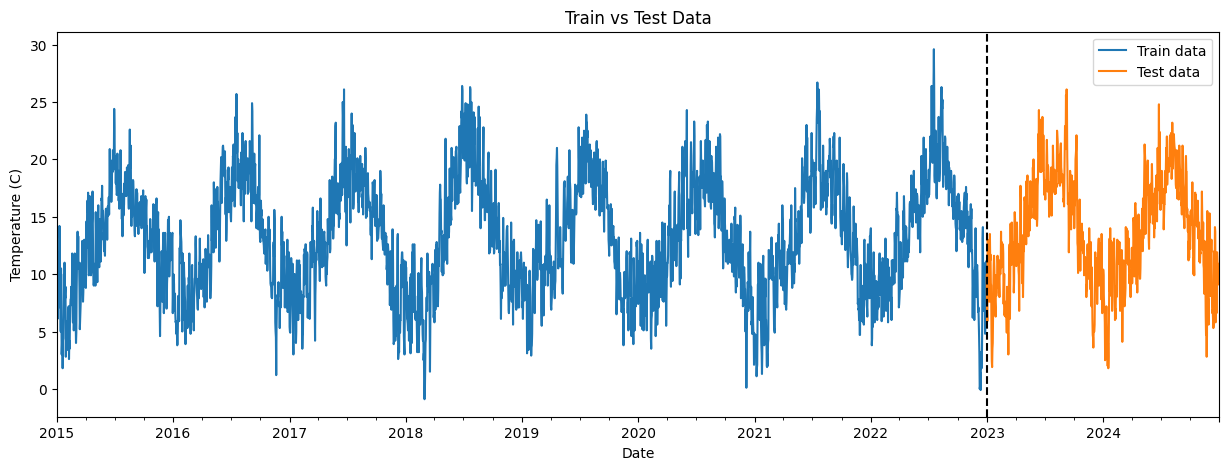

In [96]:
plt.subplots(figsize=(15, 5))
temp=train['tempmax']
tempt=test['tempmax']
temp.index=train.index
tempt.index=test.index
temp.plot(label='Train data')
tempt.plot(label='Test data')
plt.axvline('2022-12-31', color='black', ls='--')
plt.title('Train vs Test Data')
plt.xlabel('Date')
plt.ylabel('Temperature (C)')
plt.legend()
plt.show()

## Forecasting Horizon

In [5]:
# target feature
target='solarradiation'

In [6]:
# exogenous variables 
exogenous = ['tempmax','humidity','precip','windgust','windspeed',
             'winddir','sealevelpressure','cloudcover','visibility']


### Making lagg features

In [7]:
# funtion to make lagg features
def make_features(data):
    data = data.copy()
    
    #Target lags function
    for lag in range(1, 31):  #create 30 laggs
        data[f'{target}_lag{lag}'] = data[target].shift(lag)
    
    # exogenous laggs function
    for col in exogenous:
        for lag in range(1, 31): #create 30 lags of each feature
            data[f'{col}_lag{lag}'] = data[col].shift(lag)
    
  
  
    return data

In [8]:
train = make_features(train).dropna()
test  = make_features(test).dropna()

In [10]:
train.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2891 entries, 2015-01-31 to 2022-12-30
Columns: 310 entries, tempmax to visibility_lag30
dtypes: float64(310)
memory usage: 6.9 MB


In [54]:
train.columns

Index(['tempmax', 'humidity', 'precip', 'windgust', 'windspeed', 'winddir',
       'sealevelpressure', 'cloudcover', 'visibility', 'solarradiation',
       ...
       'visibility_lag21', 'visibility_lag22', 'visibility_lag23',
       'visibility_lag24', 'visibility_lag25', 'visibility_lag26',
       'visibility_lag27', 'visibility_lag28', 'visibility_lag29',
       'visibility_lag30'],
      dtype='object', length=310)

In [9]:
# Function to add features exepts for solarradiation
features = [c for c in train.columns if c != target]


In [12]:
features

['tempmax',
 'humidity',
 'precip',
 'windgust',
 'windspeed',
 'winddir',
 'sealevelpressure',
 'cloudcover',
 'visibility',
 'solarradiation_lag1',
 'solarradiation_lag2',
 'solarradiation_lag3',
 'solarradiation_lag4',
 'solarradiation_lag5',
 'solarradiation_lag6',
 'solarradiation_lag7',
 'solarradiation_lag8',
 'solarradiation_lag9',
 'solarradiation_lag10',
 'solarradiation_lag11',
 'solarradiation_lag12',
 'solarradiation_lag13',
 'solarradiation_lag14',
 'solarradiation_lag15',
 'solarradiation_lag16',
 'solarradiation_lag17',
 'solarradiation_lag18',
 'solarradiation_lag19',
 'solarradiation_lag20',
 'solarradiation_lag21',
 'solarradiation_lag22',
 'solarradiation_lag23',
 'solarradiation_lag24',
 'solarradiation_lag25',
 'solarradiation_lag26',
 'solarradiation_lag27',
 'solarradiation_lag28',
 'solarradiation_lag29',
 'solarradiation_lag30',
 'tempmax_lag1',
 'tempmax_lag2',
 'tempmax_lag3',
 'tempmax_lag4',
 'tempmax_lag5',
 'tempmax_lag6',
 'tempmax_lag7',
 'tempmax_lag8

### Creating X_train, y_train, X_test, y_test

In [10]:
X_train, y_train = train[features], train[target]
X_test,  y_test  = test[features],  test[target]

## XGBoost Model

In [11]:
model = XGBRegressor(n_estimators=200,max_depth=3, learning_rate=0.1,objective='reg:squarederror',random_state=42)

In [12]:
model.fit(X_train,y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


## Predict

In [116]:
pred = model.predict(X_test)

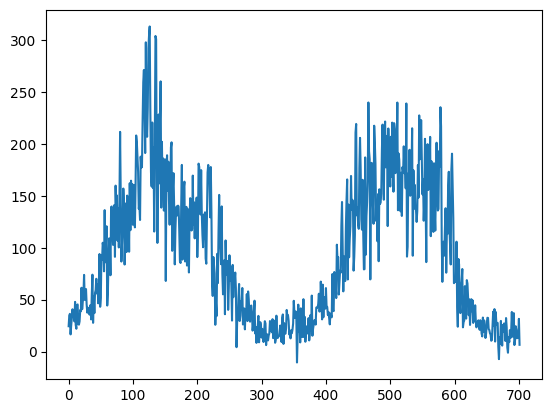

In [117]:
plt.plot(pred)

## Plot Actual vs Prediction

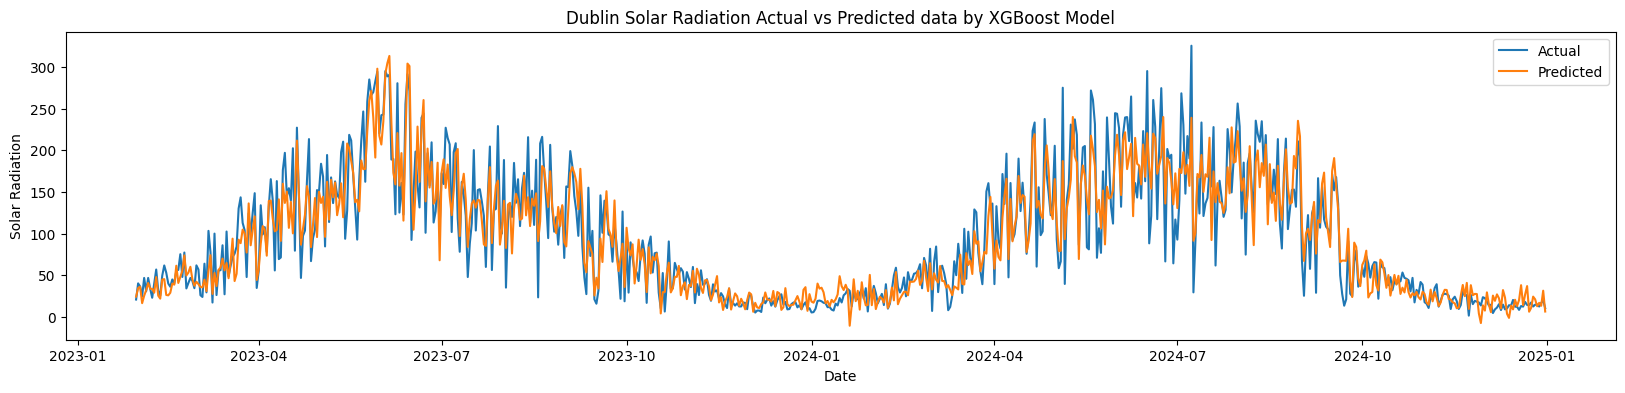

In [118]:
#y_test = y_test.reset_index(drop=True)
plt.figure(figsize =(20,4))
plt.plot(test.index,test['solarradiation'], label='Actual')
plt.plot(test.index,pred,label='Predicted')
plt.title('Dublin Solar Radiation Actual vs Predicted data by XGBoost Model')
plt.xlabel('Date')
plt.ylabel('Solar Radiation')
plt.legend()
plt.show()

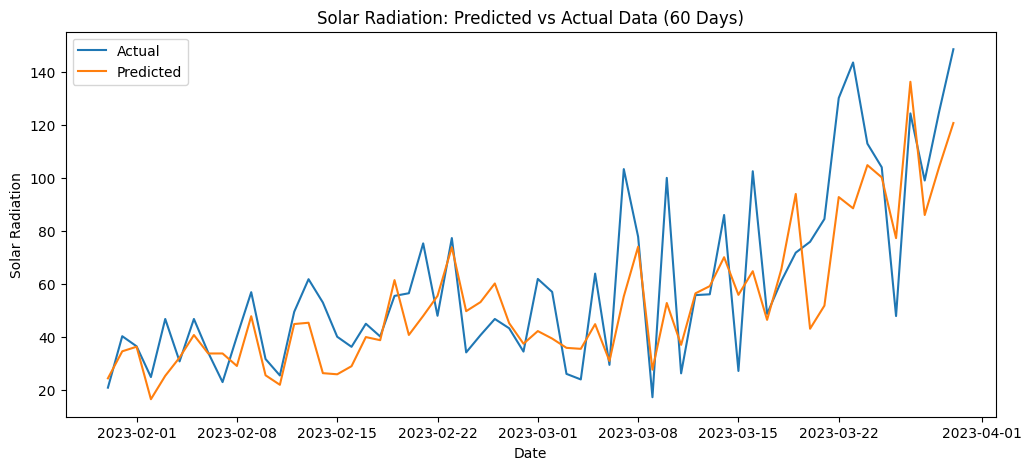

In [119]:
plt.figure(figsize=(12,5))
t=test['solarradiation']
plt.plot(t[:60], label="Actual")
plt.plot(test.index[:60],pred[:60], label="Predicted")
plt.legend()
plt.ylabel('Solar Radiation')
plt.xlabel('Date')
plt.title("Solar Radiation: Predicted vs Actual Data (60 Days)")
plt.show()

## Statistics Evaluation Metrics

In [120]:
# Calculate metrics
rmse = np.sqrt(mean_squared_error(test['solarradiation'], pred))
mae = mean_absolute_error(test['solarradiation'], pred)
r2 = r2_score(test['solarradiation'], pred)
mape =mean_absolute_percentage_error(test['solarradiation'],pred)
# Print them
print(f'RMSE: {rmse:.4f}')
print(f'MAE: {mae:.4f}')
print(f'R² score: {r2:.4f}')
print(f'MAPE: {mape:.4f}')

RMSE: 28.9239
MAE: 21.1729
R² score: 0.8498
MAPE: 0.3634


In [121]:
# Symmetric Mean Absolute Percentae Error Function
def smape(test, pred):
    test, pred = np.array(y_test), np.array(pred)
    return 100 * np.mean(2 * np.abs(pred - test) /
                         (np.abs(test) + np.abs(pred) + 1e-8))


In [122]:
print("SMAPE:", smape(test['solarradiation'], pred))


SMAPE: 30.212428609984375


## Checking Overfitting

In [123]:
p_train = model.predict(X_train)
p_test  = model.predict(X_test)
#p_test = np.expm1(p_test) test['solarradiation']

rmse_train_1 = np.sqrt(mean_squared_error(train['solarradiation'], p_train))
rmse_train_ = np.sqrt(mean_squared_error(train['solarradiation'], p_train))
rmse_test_  = np.sqrt(mean_squared_error(test['solarradiation'],  p_test))
r2_train_   = r2_score(train['solarradiation'], p_train)
r2_test_    = r2_score(test['solarradiation'],  p_test)

print(f"Train RMSE: {rmse_train_:}, Test RMSE: {rmse_test_:}")
print(f"Train R²:   {r2_train_:}, Test R²:   {r2_test_:}")

Train RMSE: 17.713121516410656, Test RMSE: 28.92393380039819
Train R²:   0.9500428324620107, Test R²:   0.8498249004836106


## Residuals Scatter Plot

A residual scatter plot displays the residuals (the differences between observed and predicted values) on the y-axis and the fitted values on the x-axis. If the points are randomly scattered around the horizontal line at zero, it indicates that the linear regression model is appropriate; patterns or trends in the plot suggest potential issues with the model, such as non-linearity or unequal variances.

Text(0.5, 1.0, 'Residuals vs Actual Values')

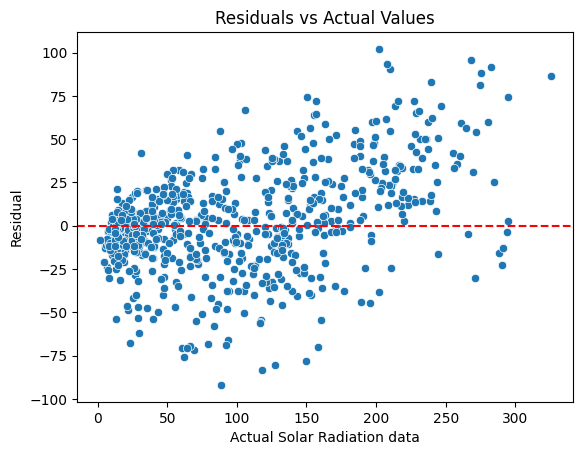

In [124]:
residuals = test['solarradiation'] - pred
sns.scatterplot(x=test['solarradiation'], y=residuals)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Actual Solar Radiation data")
plt.ylabel("Residual")
plt.title("Residuals vs Actual Values")

In [125]:
## Best Parameters by RandomizedSearchCV

Hyperparameter tuning is a process of selecting the optimal values for parameters of a machine learning model. 

Randomized Search Cross-Validation chooses the best set of parameters for a model by iterating and evaluating through all possible combinations of given parameters.

### Parameters Range

A parameters grid in the form of a python dictionary with names a values.

In [16]:
#range of parameters
param_range = {
    'n_estimators': randint(100, 2000),
    "learning_rate": loguniform(0.001, 0.3),
    'max_depth': randint(3, 12),
    "gamma": loguniform(1e-8, 10),
    "min_child_weight": loguniform(0.01, 20),
    'subsample': uniform(0.5, 0.5),
    'colsample_bytree': uniform(0.5, 0.5),
    "colsample_bylevel": uniform(0.5, 0.5),
    "colsample_bynode": uniform(0.5, 0.5),
    "reg_alpha": loguniform(1e-8, 10),                 
    "reg_lambda": loguniform(1e-8, 10),
    "max_bin": randint(128, 512),
    "grow_policy": ["depthwise", "lossguide"],
    "max_leaves": randint(0, 256),
  #  "tree_method": ["gpu_hist"],
}

### Model

In [28]:
model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

### RandomizedSearchcv 

Randomized Search samples random combinations for a predefined number of iterations from the hyperparameter grid

In [29]:
search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_range,
    n_iter=60,                    
    scoring="neg_root_mean_squared_error", 
    cv=5,
    verbose=3,
    n_jobs=-1
)

### Fit random search

In [ ]:
search.fit(X_train,y_train)

Fitting 5 folds for each of 60 candidates, totalling 300 fits


### Print Best Parameters


In [62]:
search.best_params_

{'colsample_bylevel': np.float64(0.5594749832875552),
 'colsample_bynode': np.float64(0.700045240551463),
 'colsample_bytree': np.float64(0.7053358944281223),
 'gamma': np.float64(1.6044654638852906e-05),
 'grow_policy': 'depthwise',
 'learning_rate': np.float64(0.024213531796719086),
 'max_bin': 324,
 'max_depth': 3,
 'max_leaves': 59,
 'min_child_weight': np.float64(0.294477752695693),
 'n_estimators': 1317,
 'reg_alpha': np.float64(0.010532838982435011),
 'reg_lambda': np.float64(0.4558400606414921),
 'subsample': np.float64(0.7161597120876639),
 'tree_method': 'gpu_hist'}

In [71]:
search.best_score_

np.float64(-33.051525181790346)

## XGBoost with Best Parameters

In [13]:
model_best = XGBRegressor(objective='reg:squarederror',random_state=42,
colsample_bylevel= float(0.5594749832875552),
 colsample_bynode=float(0.700045240551463),
 colsample_bytree= float(0.7053358944281223),
 gamma= float(1.6044654638852906e-05),
 grow_policy= 'depthwise',
 learning_rate= float(0.024213531796719086),
 max_bin= int(324),
 max_depth=int(3),
 max_leaves= int(59),
 min_child_weight= float(0.294477752695693),
 n_estimators= int(1317),
 reg_alpha= float(0.010532838982435011),
 reg_lambda= float(0.4558400606414921),
 subsample= float(0.7161597120876639))
                         # tree_method = "hist", device = "cuda")
                      


### Train the model with Best Parameters

In [14]:
model_best.fit(
    X_train, y_train,
    verbose=False
)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,0.5594749832875552
,colsample_bynode,0.700045240551463
,colsample_bytree,0.7053358944281223
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


### Predict

In [15]:
pred_best = model_best.predict(X_test)

### Checking Accuracy

In [129]:
# Calculate metrics
#pred_best = np.expm1(pred_best)
rmse = np.sqrt(mean_squared_error(test['solarradiation'], pred_best))
mae = mean_absolute_error(test['solarradiation'], pred_best)
r2 = r2_score(test['solarradiation'], pred_best)
mape =mean_absolute_percentage_error(test['solarradiation'],pred_best)
# Print them
print(f'RMSE: {rmse:.4f}')
print(f'MAE: {mae:.4f}')
print(f'R² score: {r2:.4f}')
print(f'MAPE: {mape:.4f}')

RMSE: 28.6734
MAE: 21.1591
R² score: 0.8524
MAPE: 0.3577


In [130]:
print("SMAPE:", smape(test['solarradiation'], pred_best))

SMAPE: 30.286901238078347


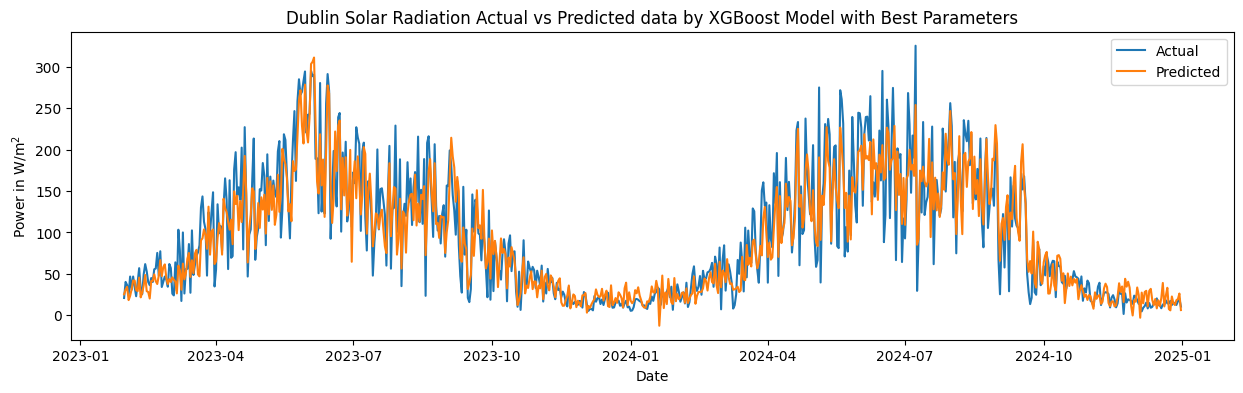

In [25]:
#test = test.reset_index(drop=True)
plt.figure(figsize =(15,4))
plt.plot(test.index,test['solarradiation'], label='Actual')
plt.plot(test.index,pred_best,label='Predicted')
plt.title('Dublin Solar Radiation Actual vs Predicted data by XGBoost Model with Best Parameters')
plt.xlabel('Date')
plt.ylabel('Power in W/m$^2$')
plt.legend()
plt.show()

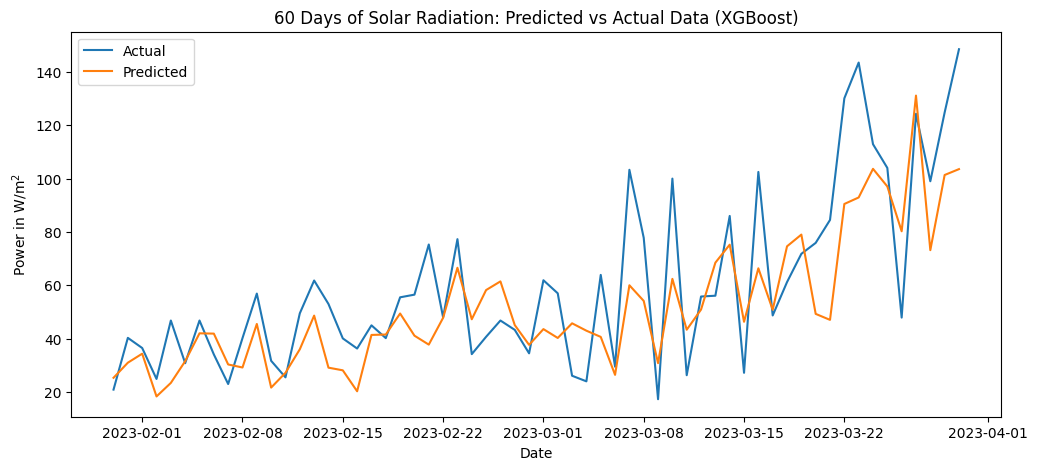

In [26]:
plt.figure(figsize=(12,5))
plt.plot(test.index[:60], test['solarradiation'][:60], label="Actual")
plt.plot(test.index[:60],pred_best[:60], label="Predicted")
plt.legend()
plt.ylabel('Power in W/m$^2$')
plt.xlabel('Date')
plt.title("60 Days of Solar Radiation: Predicted vs Actual Data (XGBoost)")
plt.show()

### Checking Overfitting with Hyperparameters

In [16]:
pred_train = model_best.predict(X_train)
pred_test  = model_best.predict(X_test)
#pred_test = np.expm1(pred_test)
rmse_train = np.sqrt(mean_squared_error(y_train, pred_train))
rmse_test  = np.sqrt(mean_squared_error(y_test,  pred_test))
r2_train   = r2_score(y_train, pred_train)
r2_test    = r2_score(y_test,  pred_test)

print(f"Train RMSE: {rmse_train}, Test RMSE: {rmse_test:}")
print(f"Train R²:   {r2_train:}, Test R²:   {r2_test:}")


Train RMSE: 14.068044318130395, Test RMSE: 28.74918599330281
Train R²:   0.9684880659837414, Test R²:   0.8516340247130034


### feature importance

<Axes: >

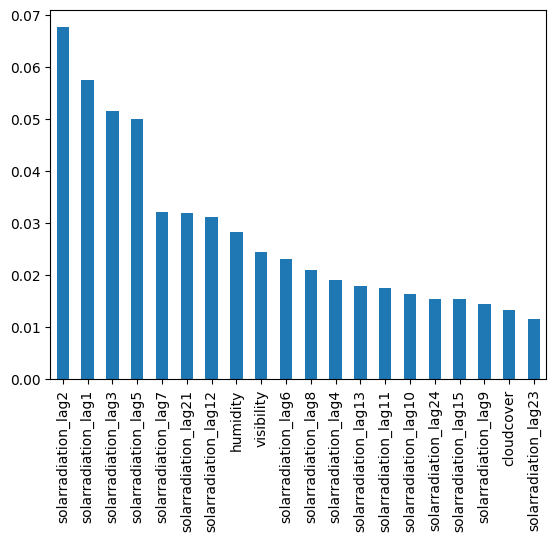

In [31]:
importances = model_best.feature_importances_

feat_imp = pd.Series(importances, index=X_train.columns).sort_values(ascending=False)
feat_imp.head(20).plot(kind='bar')

### Residual

A residual is the difference between the actual data and the predicted data. 

Text(0.5, 1.0, 'Distribution of Residuals')

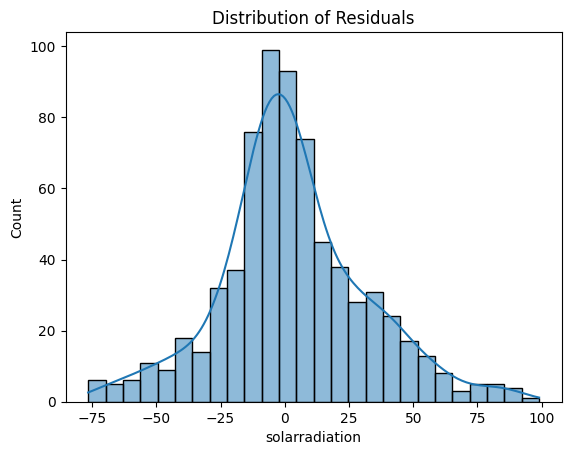

In [17]:
residuals = y_test - pred_best
sns.histplot(residuals, kde=True)
plt.title("Distribution of Residuals")


Text(0.5, 1.0, 'Residuals vs Actual Values (XGBoost model)')

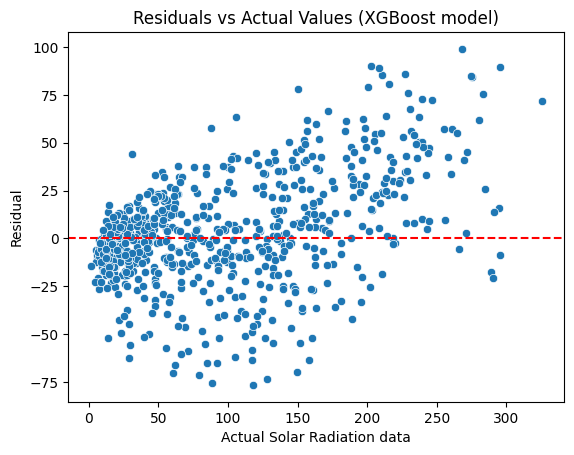

In [19]:
residuals = y_test - pred_best
sns.scatterplot(x=y_test, y=residuals)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Actual Solar Radiation data")
plt.ylabel("Residual")
plt.title("Residuals vs Actual Values (XGBoost model)")


Observations:
Residuals are centered around 0, indication no bias.
High Range of Solar radiation values, the model fails to predict very high solar radiation

## SHAP

SHAP is a method that helps us understand how a machine learning model makes decisions. It tells us how much each input (feature) is helping or hurting the final prediction. The main idea is to fairly distribute the "payout" (the prediction) among all features based on their contribution.

In [27]:
import shap
explainer = shap.Explainer(model_best)
shap_values = explainer(X_test)
shap.initjs()

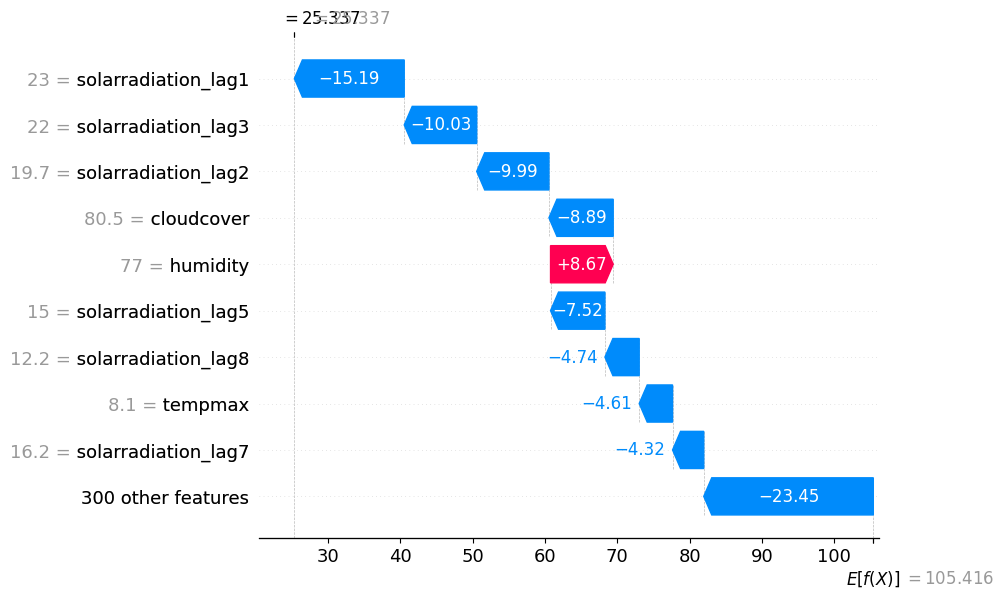

In [28]:
shap.waterfall_plot(shap_values[0])

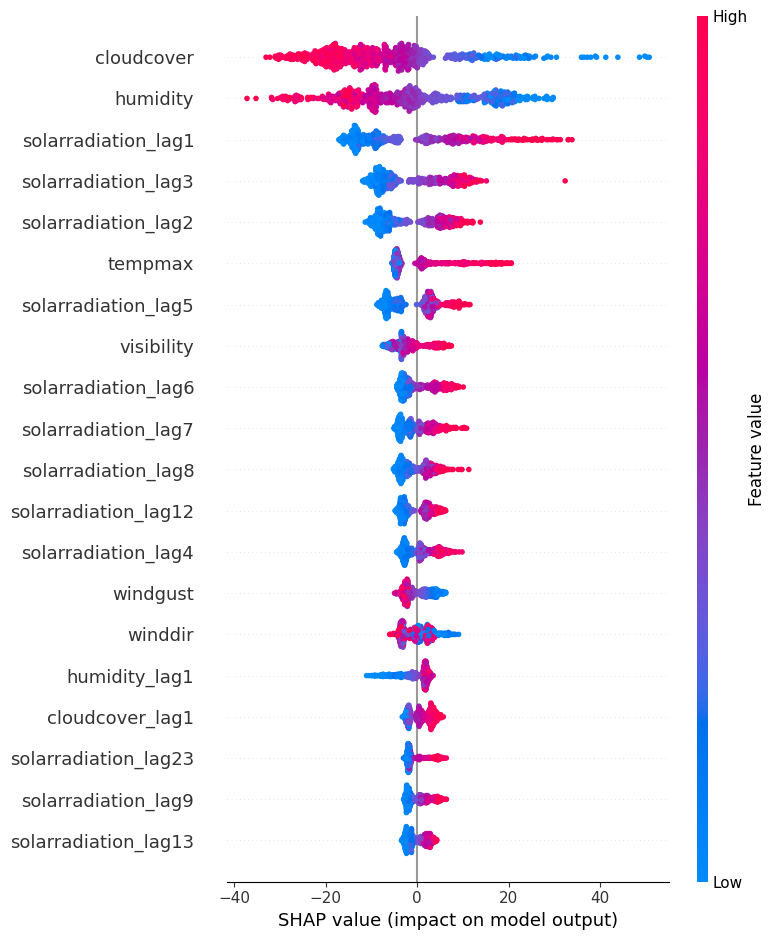

<Figure size 640x480 with 0 Axes>

In [33]:
shap.summary_plot(shap_values, X_test)
plt.show()
plt.savefig('shap.png',dpi=300)


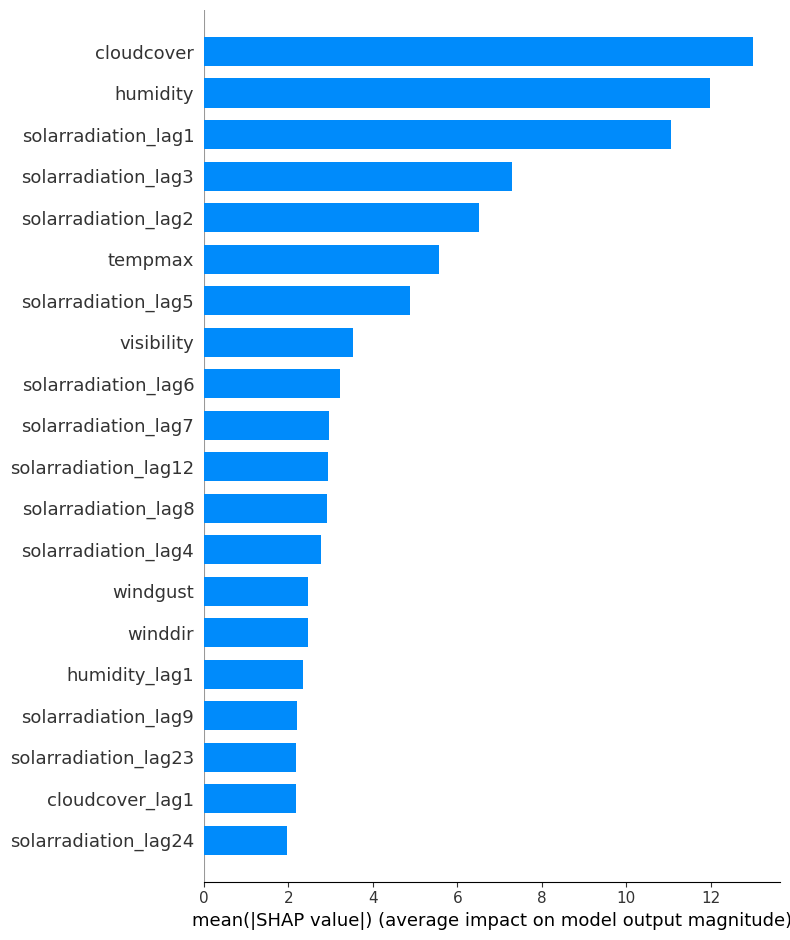

In [38]:
shap.summary_plot(shap_values, X_test, plot_type="bar")

SHAP analysis was applied to quantify the contribution of each input variable to the XGBoost predictions.

The most influential features were 'cloudcover' and 'humidity', which had the greatest negative influence. In addition, 'solarradiation_lag1' showed  the most positive influence, confirming the strong persistence of solar irradiance.

This indicates that the model correctly learned the physical dependencies: higher humidity and cloudiness reduce solar input, whereas clearer and warmer conditions increase irradiance.

Secondary features such as wind speed, visibility, and precipitation had smaller but consistent impacts.

The 'solarradiation' variable showed right-skeed distribution, due to natural variability. To stabilize variance and improve model performance, a logarithmic transformation was applied.

The log transform compress large values, stabilize variance, and make distributions more normal, according to Best practice in statistics: The use of log transformation by West(2021).

# Experiment 2:
To develop a XGBoost Model applying **differencing** to the target feature.

**Differencing** in time series is a technique used to remove trends or seasonal effects by calculating the difference between consecutive observations. This helps to stabilize the mean of the time series and make it stationary, which is important for accurate forecasting.

## Libraries

In [1]:
# Data manipulation
import pandas as pd
import numpy as np
##Plots
import matplotlib.pyplot as plt
import seaborn as sns

#Split the data
from sklearn.model_selection import train_test_split

#XGBoost model
from xgboost import XGBRegressor

# Statistical Evaluation Metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from math import sqrt

#randomized seach CV
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform
import random

## Load the Dataset

In [4]:
df = pd.read_csv('dublin_2015_to_2024_final.csv',parse_dates=["datetime"])
df.head()

,datetime,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation
0,2015-01-01,13.6,82.9,4.786,95.8,64.0,220.5,1013.4,86.1,17.1,8.8
1,2015-01-02,7.0,73.1,0.451,68.5,40.9,241.5,1026.9,49.4,20.9,39.2
2,2015-01-03,6.1,93.9,7.283,37.1,28.1,301.3,1023.8,64.0,15.6,16.9
3,2015-01-04,6.8,93.5,0.000,33.8,13.1,191.4,1031.3,54.9,18.9,20.1
4,2015-01-05,10.7,88.6,0.026,41.4,25.5,182.2,1021.3,89.5,19.8,9.8


## Differencing technique

In [5]:
df['solarradiation_diff'] = df['solarradiation'].diff()

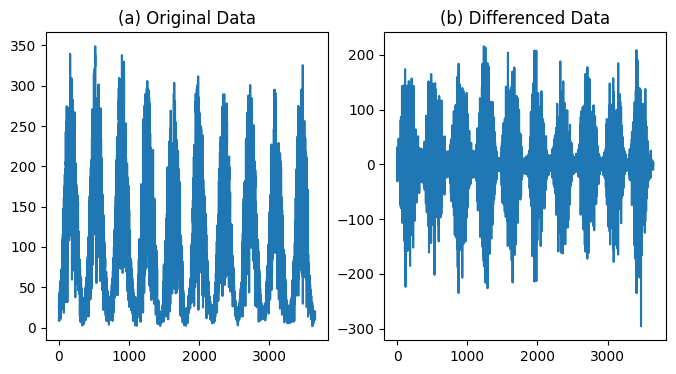

In [6]:
plt.figure(figsize=(8,4))
plt.subplot(1, 2, 1)
plt.plot(df['solarradiation'])
plt.title("(a) Original Data")

plt.subplot(1, 2, 2)
plt.plot(df['solarradiation_diff'])
plt.title("(b) Differenced Data")
plt.show()

## Split into Train and Test data (80/20)

In [7]:
df.set_index("datetime", inplace=True)
df = df.sort_index()

In [8]:
# Separate historical and future data
train = df.loc[df.index < '2022-12-31']
test = df.loc[df.index >= '2022-12-31'].copy()

In [9]:
train=train.drop('solarradiation',axis=1)
train = train.dropna()

In [10]:
test=test.drop('solarradiation',axis=1)
test= test.dropna()

In [220]:
train.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2920 entries, 2015-01-02 to 2022-12-30
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   tempmax              2920 non-null   float64
 1   humidity             2920 non-null   float64
 2   precip               2920 non-null   float64
 3   windgust             2920 non-null   float64
 4   windspeed            2920 non-null   float64
 5   winddir              2920 non-null   float64
 6   sealevelpressure     2920 non-null   float64
 7   cloudcover           2920 non-null   float64
 8   visibility           2920 non-null   float64
 9   solarradiation_diff  2920 non-null   float64
dtypes: float64(10)
memory usage: 250.9 KB


## Forecasting Horizon

In [11]:
# target feature
target='solarradiation_diff'

In [12]:
# exogenous variables 
exogenous = ['tempmax','humidity','precip','windgust','windspeed',
             'winddir','sealevelpressure','cloudcover','visibility']


### Making lagg features

In [13]:
# funtion to make lagg features
def make_features(data):
    data = data.copy()
    
    #Target lags function
    for lag in range(1, 31):  #create 30 laggs
        data[f'{target}_lag{lag}'] = data[target].shift(lag)
    
    # exogenous laggs function
    for col in exogenous:
        for lag in range(1, 31): #create 30 lags of each feature
            data[f'{col}_lag{lag}'] = data[col].shift(lag)
    
  
  
    return data

In [14]:
train = make_features(train).dropna()
test  = make_features(test).dropna()

In [151]:
train.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2890 entries, 2015-02-01 to 2022-12-30
Columns: 310 entries, tempmax to visibility_lag30
dtypes: float64(310)
memory usage: 6.9 MB


In [152]:
train.columns

Index(['tempmax', 'humidity', 'precip', 'windgust', 'windspeed', 'winddir',
       'sealevelpressure', 'cloudcover', 'visibility', 'solarradiation_diff',
       ...
       'visibility_lag21', 'visibility_lag22', 'visibility_lag23',
       'visibility_lag24', 'visibility_lag25', 'visibility_lag26',
       'visibility_lag27', 'visibility_lag28', 'visibility_lag29',
       'visibility_lag30'],
      dtype='object', length=310)

In [15]:
# Function to add features exepts for solarradiation
features = [c for c in train.columns if c != target]


In [155]:
features

AttributeError: 'list' object has no attribute 'head'

### Creating X_train, y_train, X_test, y_test

In [16]:
X_train, y_train = train[features], train[target]
X_test,  y_test  = test[features],  test[target]

In [157]:
y_test

datetime
2023-01-30    -2.1
2023-01-31    19.4
2023-02-01    -3.8
2023-02-02   -11.6
2023-02-03    21.9
              ... 
2024-12-27     0.3
2024-12-28    -2.5
2024-12-29     4.3
2024-12-30     3.3
2024-12-31    -9.6
Name: solarradiation_diff, Length: 702, dtype: float64

## XGBoost Model

In [17]:
model = XGBRegressor(n_estimators=200,max_depth=3, learning_rate=0.1,objective='reg:squarederror',random_state=42)

In [18]:
model.fit(X_train,y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


## Predict

In [177]:
pred = model.predict(X_test)

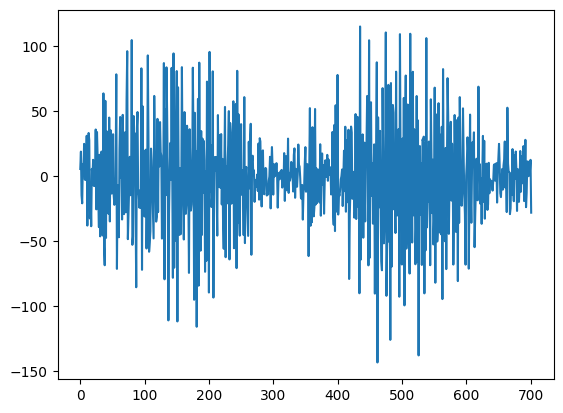

In [178]:
plt.plot(pred)

## Undo Differencing

In [ ]:
df = pd.read_csv('dublin_2015_to_2024_final.csv',parse_dates=["datetime"])
df.set_index("datetime", inplace=True)


In [184]:
train_org = df.loc[df.index < '2022-12-31'].copy()
test_org= df.loc[df.index >= '2022-12-31'].copy()

In [185]:
# last actual value before test starts
last_train_value = train_org['solarradiation'].iloc[-1]

# make into a Series to handle cumulative sum easily
y_pred_diff = pd.Series(pred)

# reconstruct original scale
y_pred_original = last_train_value + np.cumsum(y_pred_diff)


In [181]:
# last actual value before test starts
last_train_value =  df['solarradiation'].loc[df.index < '2022-12-31']

# make into a Series to handle cumulative sum easily
y_pred_diff = pd.Series(pred)

# reconstruct original scale
y_pred_original = last_train_value + np.cumsum(y_pred_diff)

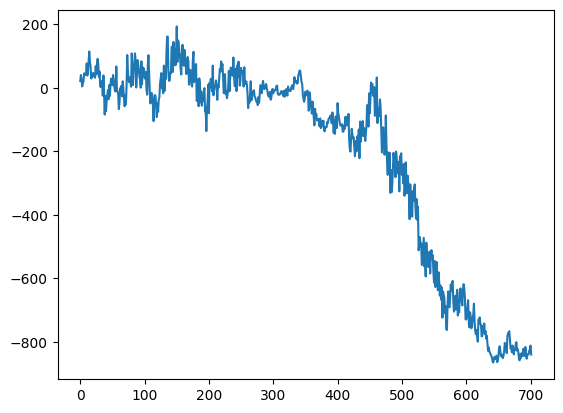

In [187]:
plt.plot(y_pred_original)

## Plot Actual vs Prediction

In [172]:
df = pd.read_csv('dublin_2015_to_2024_final.csv',parse_dates=["datetime"])
df.set_index("datetime", inplace=True)
test_org= df.loc[df.index >= '2022-12-31'].copy()

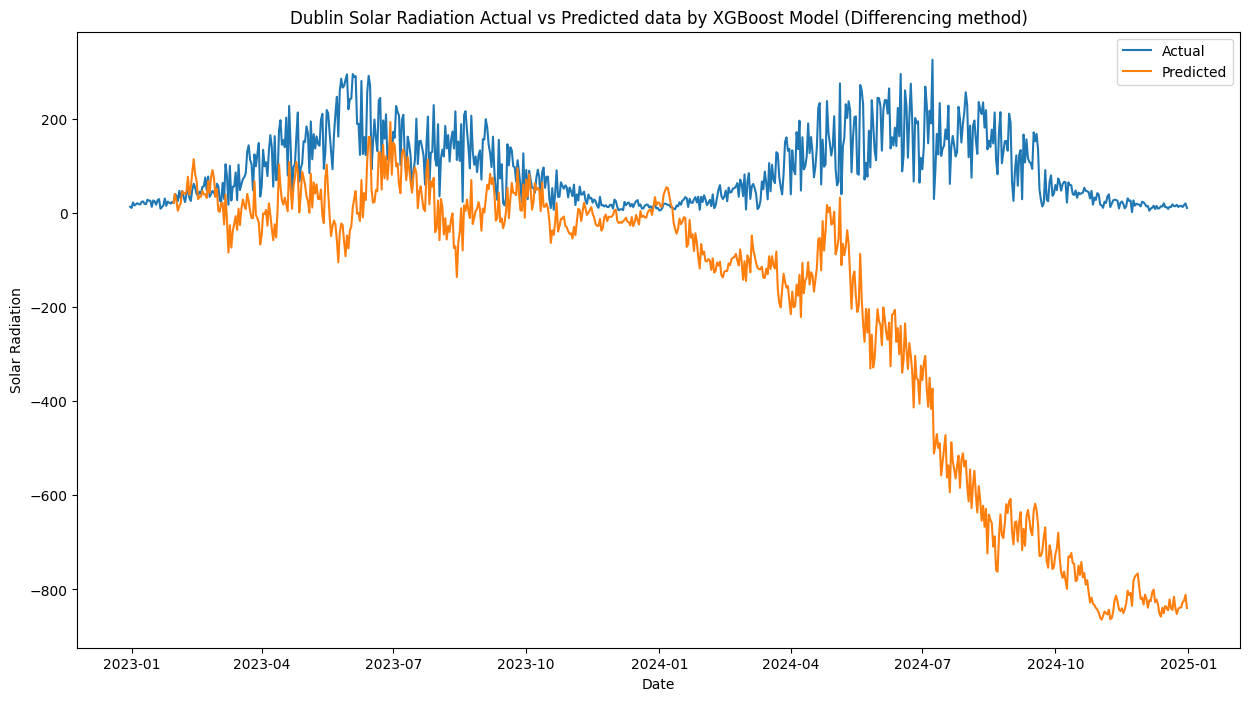

In [192]:
#y_test = test.reset_index(drop=True)
plt.figure(figsize =(15,8))
plt.plot(test_org['solarradiation'], label='Actual')
plt.plot(X_test.index,y_pred_original,label='Predicted')
plt.title('Dublin Solar Radiation Actual vs Predicted data by XGBoost Model (Differencing method)')
plt.xlabel('Date')
plt.ylabel('Solar Radiation')
plt.legend()
plt.show()

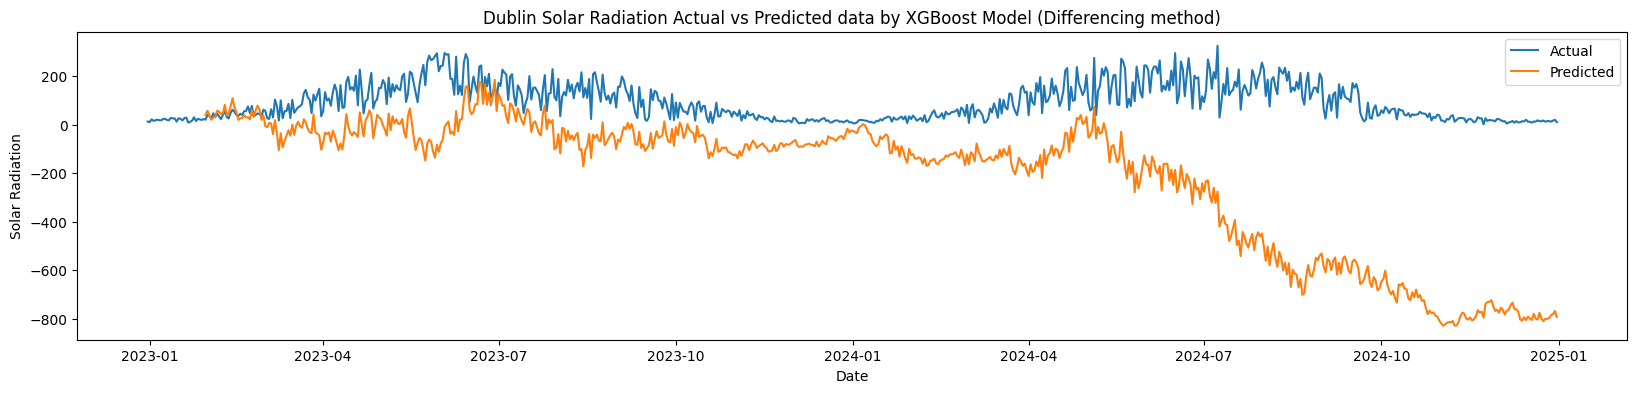

In [175]:
y_test = test.reset_index(drop=True)
plt.figure(figsize =(20,4))
plt.plot(test_o['solarradiation'], label='Actual')
plt.plot(X_test.index,y_pred_original,label='Predicted')
plt.title('Dublin Solar Radiation Actual vs Predicted data by XGBoost Model (Differencing method)')
plt.xlabel('Date')
plt.ylabel('Solar Radiation')
plt.legend()
plt.show()

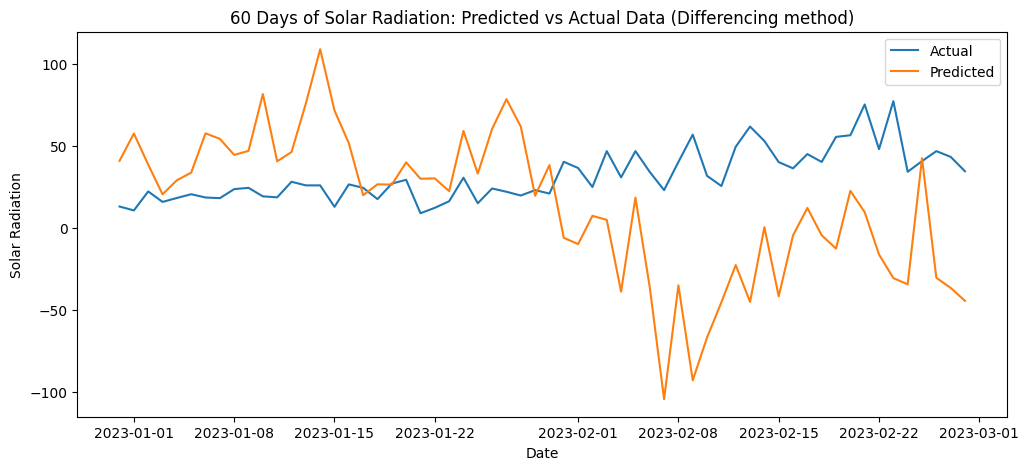

In [176]:
plt.figure(figsize=(12,5))
t=test_o['solarradiation']
plt.plot(t[:60], label="Actual")
plt.plot(test.index[:60],y_pred_original[:60], label="Predicted")
plt.legend()
plt.ylabel('Solar Radiation')
plt.xlabel('Date')
plt.title("60 Days of Solar Radiation: Predicted vs Actual Data (Differencing method)")
plt.show()

## Statistics Evaluation Metrics

In [194]:
# Calculate metrics
rmse = np.sqrt(mean_squared_error(test_org['solarradiation'][30:], y_pred_original))
mae = mean_absolute_error(test_org['solarradiation'][30:], y_pred_original)
r2 = r2_score(test_org['solarradiation'][30:], y_pred_original)
mape =mean_absolute_percentage_error(test_org['solarradiation'][30:],y_pred_original)
# Print them
print(f'RMSE: {rmse:.4f}')
print(f'MAE: {mae:.4f}')
print(f'R² score: {r2:.4f}')
print(f'MAPE: {mape:.4f}')

RMSE: 437.8459
MAE: 309.8212
R² score: -33.4133
MAPE: 8.8903


In [155]:
# Symmetric Mean Absolute Percentae Error Function
def smape(test, pred):
    test, pred = np.array(y_test), np.array(pred)
    return 100 * np.mean(2 * np.abs(pred - test) /
                         (np.abs(test) + np.abs(pred) + 1e-8))


In [195]:
print("SMAPE:", smape(test_org['solarradiation'][30:], y_pred_original[0]))


SMAPE: 105.93739268920265


### Best parameters by randomizedserachcv

A parameters grid in the form of a python dictionary with names a values.

In [19]:
#range of parameters
param_range = {
    'n_estimators': randint(100, 2000),
    "learning_rate": loguniform(0.001, 0.3),
    'max_depth': randint(3, 12),
    "gamma": loguniform(1e-8, 10),
    "min_child_weight": loguniform(0.01, 20),
    'subsample': uniform(0.5, 0.5),
    'colsample_bytree': uniform(0.5, 0.5),
    "colsample_bylevel": uniform(0.5, 0.5),
    "colsample_bynode": uniform(0.5, 0.5),
    "reg_alpha": loguniform(1e-8, 10),                 
    "reg_lambda": loguniform(1e-8, 10),
    "max_bin": randint(128, 512),
    "grow_policy": ["depthwise", "lossguide"],
    "max_leaves": randint(0, 256),
  #  "tree_method": ["gpu_hist"],
}

In [20]:
model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

Randomized Search samples random combinations for a predefined number of iterations from the hyperparameter grid

In [21]:
search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_range,
    n_iter=20,                    
    scoring="neg_root_mean_squared_error", 
    cv=5,
    verbose=3,
    n_jobs=-1
)

In [22]:
search.fit(X_train,y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,estimator,"XGBRegressor(...ree=None, ...)"
,param_distributions,"{'colsample_bylevel': <scipy.stats....001AB0BFEBB60>, 'colsample_bynode': <scipy.stats....001AB0BFE98E0>, 'colsample_bytree': <scipy.stats....001AB0BFEAA50>, 'gamma': <scipy.stats....001AB0BFEAD50>, ...}"
,n_iter,20
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,3
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [23]:
search.best_params_

{'colsample_bylevel': np.float64(0.9782698796597045),
 'colsample_bynode': np.float64(0.7273890013679556),
 'colsample_bytree': np.float64(0.7741750010295139),
 'gamma': np.float64(4.060487682798381),
 'grow_policy': 'lossguide',
 'learning_rate': np.float64(0.013636613583564262),
 'max_bin': 205,
 'max_depth': 3,
 'max_leaves': 57,
 'min_child_weight': np.float64(4.846471606047243),
 'n_estimators': 1824,
 'reg_alpha': np.float64(2.3590552126366903e-06),
 'reg_lambda': np.float64(0.006723309318627458),
 'subsample': np.float64(0.6294856961907067)}

In [24]:
search.best_score_

np.float64(-36.47091721912749)

In [25]:
model_best = XGBRegressor(objective='reg:squarederror',random_state=42,
colsample_bylevel= float(0.9782698796597045),
 colsample_bynode=float(0.7273890013679556),
 colsample_bytree= float(0.7741750010295139),
 gamma= float(4.060487682798381),
 grow_policy= 'lossguide',
 learning_rate= float(0.013636613583564262),
 max_bin= 205,
 max_depth=(3),
 max_leaves= 57,
 min_child_weight= float(4.846471606047243),
 n_estimators= 1824,
 reg_alpha= float(2.3590552126366903e-06),
 reg_lambda= float(0.006723309318627458),
 subsample= float(0.6294856961907067))          


In [26]:
model_best.fit(
    X_train, y_train,
    verbose=False
)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,0.9782698796597045
,colsample_bynode,0.7273890013679556
,colsample_bytree,0.7741750010295139
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [27]:
pred_best = model_best.predict(X_test)

## Undo Differencing

In [28]:
df = pd.read_csv('dublin_2015_to_2024_final.csv',parse_dates=["datetime"])
df.set_index("datetime", inplace=True)


In [29]:
train_org = df.loc[df.index < '2022-12-31'].copy()
test_org= df.loc[df.index >= '2022-12-31'].copy()

In [45]:
# last actual value before test starts
last_train_value = test_org['solarradiation'].iloc[30]

# make into a Series to handle cumulative sum easily
y_pred_diff = pd.Series(pred_best)

# reconstruct original scale
y_pred_original = last_train_value + np.cumsum(y_pred_diff)


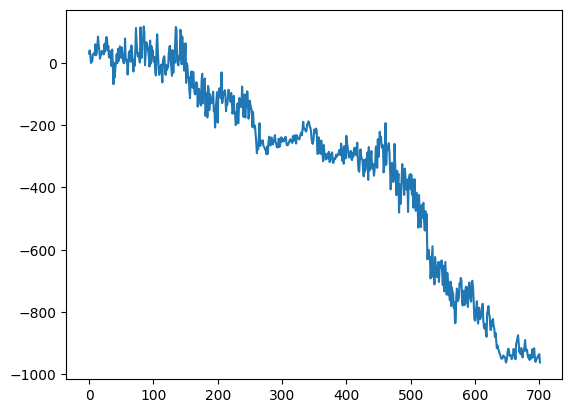

In [46]:
plt.plot(y_pred_original)

## Plot Actual vs Prediction

In [172]:
df = pd.read_csv('dublin_2015_to_2024_final.csv',parse_dates=["datetime"])
df.set_index("datetime", inplace=True)
test_org= df.loc[df.index >= '2022-12-31'].copy()

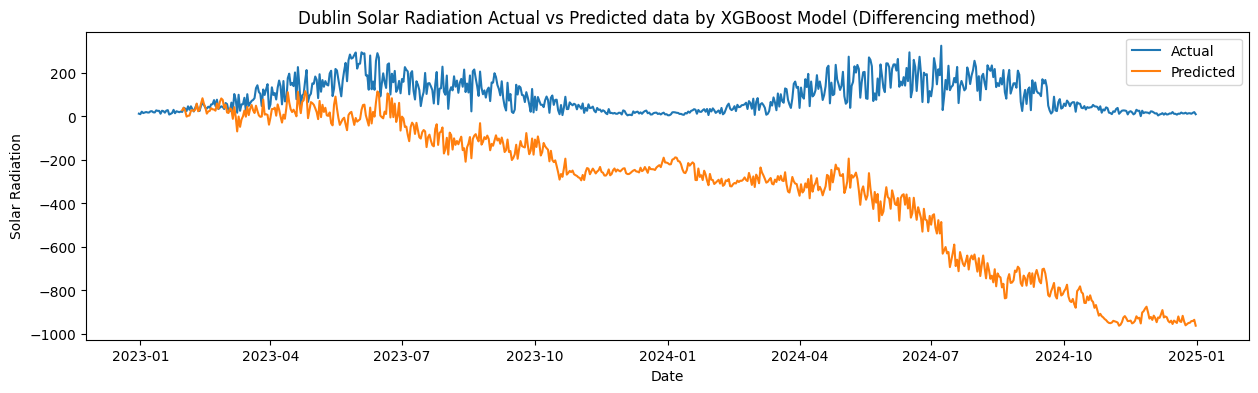

In [50]:
#y_test = test.reset_index(drop=True)
plt.figure(figsize =(15,4))
plt.plot(test_org['solarradiation'], label='Actual')
plt.plot(X_test.index,y_pred_original,label='Predicted')
plt.title('Dublin Solar Radiation Actual vs Predicted data by XGBoost Model (Differencing method)')
plt.xlabel('Date')
plt.ylabel('Solar Radiation')
plt.legend()
plt.show()

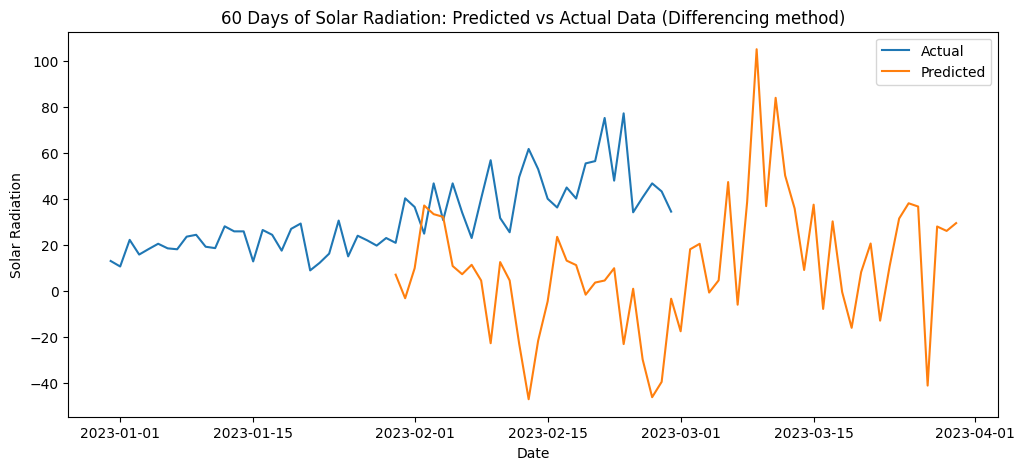

In [38]:
plt.figure(figsize=(12,5))
t=test_org['solarradiation']
plt.plot(t[:60], label="Actual")
plt.plot(test.index[:60],y_pred_original[:60], label="Predicted")
plt.legend()
plt.ylabel('Solar Radiation')
plt.xlabel('Date')
plt.title("60 Days of Solar Radiation: Predicted vs Actual Data (Differencing method)")
plt.show()

## Statistics Evaluation Metrics

In [44]:
# Calculate metrics
rmse = np.sqrt(mean_squared_error(test_org['solarradiation'][30:], y_pred_original))
mae = mean_absolute_error(test_org['solarradiation'][30:], y_pred_original)
r2 = r2_score(test_org['solarradiation'][30:], y_pred_original)
mape =mean_absolute_percentage_error(test_org['solarradiation'][30:],y_pred_original)
# Print them
print(f'RMSE: {rmse:.4f}')
print(f'MAE: {mae:.4f}')
print(f'R² score: {r2:.4f}')
print(f'MAPE: {mape:.4f}')

RMSE: 531.7235
MAE: 434.8972
R² score: -49.7522
MAPE: 12.9393


In [40]:
# Symmetric Mean Absolute Percentae Error Function
def smape(test, pred):
    test, pred = np.array(y_test), np.array(pred)
    return 100 * np.mean(2 * np.abs(pred - test) /
                         (np.abs(test) + np.abs(pred) + 1e-8))


In [41]:
print("SMAPE:", smape(test_org['solarradiation'][30:], y_pred_original[0]))


SMAPE: 141.74969678643225


In [83]:
print("SMAPE:", smape(test['solarradiation'], pred_best))

SMAPE: 30.381045579004436


In [21]:
pred_best.shape

(702,)

In [23]:
pred_train = model_best.predict(X_train)
pred_test  = model_best.predict(X_test)
#pred_test = np.expm1(pred_test)
rmse_train = np.sqrt(mean_squared_error(y_train, pred_train))
rmse_test  = np.sqrt(mean_squared_error(y_test,  pred_test))
r2_train   = r2_score(y_train, pred_train)
r2_test    = r2_score(y_test,  pred_test)

print(f"Train RMSE: {rmse_train}, Test RMSE: {rmse_test:}")
print(f"Train R²:   {r2_train:}, Test R²:   {r2_test:}")


Train RMSE: 14.076767382385095, Test RMSE: 28.99428524027486
Train R²:   0.9684489751420359, Test R²:   0.8490934727891851


<Axes: >

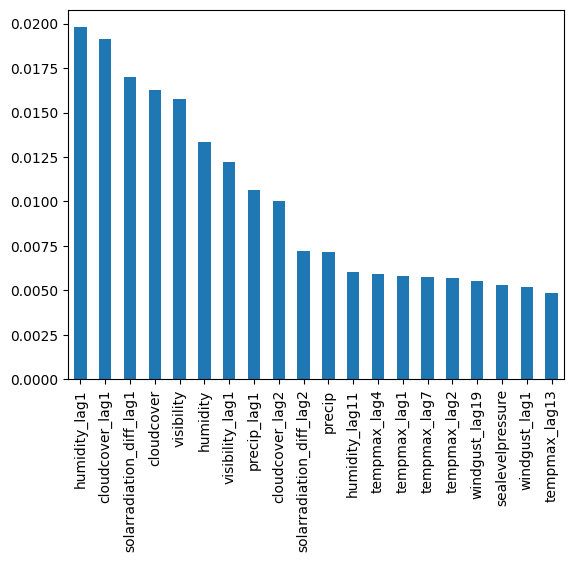

In [49]:
importances = model_best.feature_importances_

feat_imp = pd.Series(importances, index=X_train.columns).sort_values(ascending=False)
feat_imp.head(20).plot(kind='bar')

A residual is the difference between the actual data and the predicted data. 

Observations:
Residuals are centered around 0, indication no bias.
High Range of Solar radiation values, the model fails to predict very high solar radiation

In [2]:
# Data manipulation
import pandas as pd
import numpy as np
##Plots
import matplotlib.pyplot as plt
import seaborn as sns

#Split the data
from sklearn.model_selection import train_test_split

#XGBoost model
from xgboost import XGBRegressor

# Accuracy
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from math import sqrt

#random seachcv
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform
import random

# Experiment 3:
To develop a XGBoost Model for forecasting task applying **log transformation** technique to the target feature (solarradiation).

## Libraries

In [51]:
# Data manipulation
import pandas as pd
import numpy as np
##Plots
import matplotlib.pyplot as plt
import seaborn as sns

#Split the data
from sklearn.model_selection import train_test_split

#XGBoost model
from xgboost import XGBRegressor

# Statistical Evaluation Metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from math import sqrt

#randomized seach CV
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform
import random

## Load the Dataset

In [52]:
df = pd.read_csv('dublin_2015_to_2024_final.csv',parse_dates=["datetime"])
df.head()

,datetime,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation
0,2015-01-01,13.6,82.9,4.786,95.8,64.0,220.5,1013.4,86.1,17.1,8.8
1,2015-01-02,7.0,73.1,0.451,68.5,40.9,241.5,1026.9,49.4,20.9,39.2
2,2015-01-03,6.1,93.9,7.283,37.1,28.1,301.3,1023.8,64.0,15.6,16.9
3,2015-01-04,6.8,93.5,0.000,33.8,13.1,191.4,1031.3,54.9,18.9,20.1
4,2015-01-05,10.7,88.6,0.026,41.4,25.5,182.2,1021.3,89.5,19.8,9.8


## Logarithmic Transformation

The 'solarradiation' variable showed right-skeed distribution, due to natural variability. To stabilize variance and improve model performance, a logarithmic transformation was applied.

The log transform compress large values, stabilize variance, and make distributions more normal, according to Best practice in statistics: The use of log transformation by West(2021).

In [53]:
df['solarradiation'] = np.log1p(df['solarradiation'])


In [54]:
df_org= pd.read_csv("dublin_2015_to_2024_final.csv", parse_dates=["datetime"])

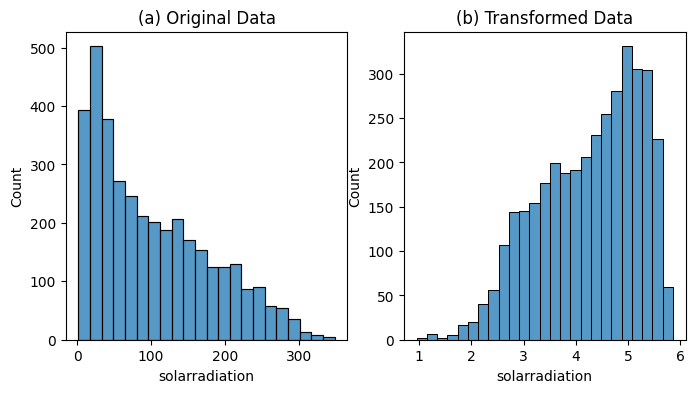

In [55]:
plt.figure(figsize=(8,4))
plt.subplot(1, 2, 1)
sns.histplot(df_org['solarradiation'])
plt.title("(a) Original Data")

plt.subplot(1, 2, 2)
sns.histplot(df['solarradiation'])
plt.title("(b) Transformed Data")
plt.show()

## Split into Train and Test data (80/20)

In [56]:
df.set_index("datetime", inplace=True)
df = df.sort_index()

In [57]:
# Separate historical and future data
train = df.loc[df.index < '2022-12-31']
test = df.loc[df.index >= '2022-12-31'].copy()

In [19]:
test

,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation
datetime,,,,,,,,,,
2022-12-31,9.9,93.0,1.523,23.4,13.8,212.2,991.8,89.9,13.4,2.639057
2023-01-01,6.8,91.8,0.735,36.4,17.9,241.6,1000.4,77.0,15.2,2.451005
2023-01-02,5.9,84.8,0.000,46.1,24.8,222.7,1014.4,44.6,15.6,3.144152
2023-01-03,13.0,85.1,0.849,78.1,36.0,202.6,1004.4,87.0,16.6,2.821379
2023-01-04,12.8,79.4,0.314,64.8,35.1,252.6,1008.0,77.1,15.7,2.954910
...,...,...,...,...,...,...,...,...,...,...
2024-12-27,9.9,95.4,0.075,17.6,12.7,201.7,1030.8,90.8,9.5,2.772589
2024-12-28,9.1,90.2,0.002,31.7,17.8,232.8,1027.7,83.9,17.0,2.602690
2024-12-29,9.9,86.2,0.078,48.2,29.1,241.1,1026.8,77.1,16.4,2.879198


## Forecasting Horizon

In [58]:
# target feature
target='solarradiation'

In [59]:
# exogenous variables 
exogenous = ['tempmax','humidity','precip','windgust','windspeed',
             'winddir','sealevelpressure','cloudcover','visibility']


### Making lagg features

In [60]:
# funtion to make lagg features
def make_features(data):
    data = data.copy()
    
    #Target lags function
    for lag in range(1, 31):  #create 30 laggs
        data[f'{target}_lag{lag}'] = data[target].shift(lag)
    
    # exogenous laggs function
    for col in exogenous:
        for lag in range(1, 31): #create 30 lags of each feature
            data[f'{col}_lag{lag}'] = data[col].shift(lag)
    
  
  
    return data

In [61]:
train = make_features(train).dropna()
test  = make_features(test).dropna()

In [24]:
train.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2891 entries, 2015-01-31 to 2022-12-30
Columns: 310 entries, tempmax to visibility_lag30
dtypes: float64(310)
memory usage: 6.9 MB


In [25]:
train.columns

Index(['tempmax', 'humidity', 'precip', 'windgust', 'windspeed', 'winddir',
       'sealevelpressure', 'cloudcover', 'visibility', 'solarradiation',
       ...
       'visibility_lag21', 'visibility_lag22', 'visibility_lag23',
       'visibility_lag24', 'visibility_lag25', 'visibility_lag26',
       'visibility_lag27', 'visibility_lag28', 'visibility_lag29',
       'visibility_lag30'],
      dtype='object', length=310)

In [62]:
# Function to add features exepts for solarradiation
features = [c for c in train.columns if c != target]


In [67]:
features

['tempmax',
 'humidity',
 'precip',
 'windgust',
 'windspeed',
 'winddir',
 'sealevelpressure',
 'cloudcover',
 'visibility',
 'solarradiation_lag1',
 'solarradiation_lag2',
 'solarradiation_lag3',
 'solarradiation_lag4',
 'solarradiation_lag5',
 'solarradiation_lag6',
 'solarradiation_lag7',
 'solarradiation_lag8',
 'solarradiation_lag9',
 'solarradiation_lag10',
 'solarradiation_lag11',
 'solarradiation_lag12',
 'solarradiation_lag13',
 'solarradiation_lag14',
 'solarradiation_lag15',
 'solarradiation_lag16',
 'solarradiation_lag17',
 'solarradiation_lag18',
 'solarradiation_lag19',
 'solarradiation_lag20',
 'solarradiation_lag21',
 'solarradiation_lag22',
 'solarradiation_lag23',
 'solarradiation_lag24',
 'solarradiation_lag25',
 'solarradiation_lag26',
 'solarradiation_lag27',
 'solarradiation_lag28',
 'solarradiation_lag29',
 'solarradiation_lag30',
 'tempmax_lag1',
 'tempmax_lag2',
 'tempmax_lag3',
 'tempmax_lag4',
 'tempmax_lag5',
 'tempmax_lag6',
 'tempmax_lag7',
 'tempmax_lag8

### Creating X_train, y_train, X_test, y_test

In [63]:
X_train, y_train = train[features], train[target]
X_test,  y_test  = test[features],  test[target]

In [64]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((2891, 309), (702, 309), (2891,), (702,))

## XGBoost Model

In [241]:
model = XGBRegressor(n_estimators=200,max_depth=3, learning_rate=0.1,objective='reg:squarederror',random_state=42)

In [242]:
model.fit(X_train,y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


## Predict

In [243]:
pred = model.predict(X_test)

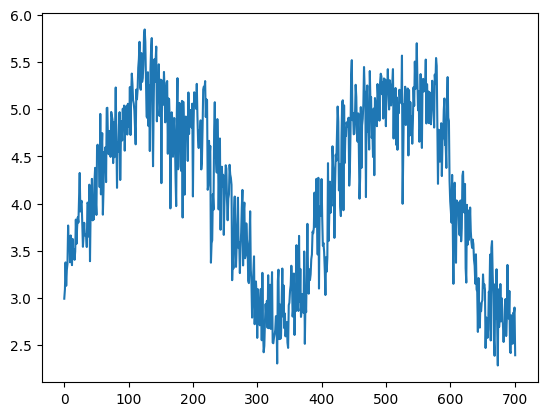

In [244]:
plt.plot(pred)

## Inverse Transformation

In [245]:
pred = np.expm1(pred)
y_test=np.expm1(y_test)

## Plot Actual vs Prediction

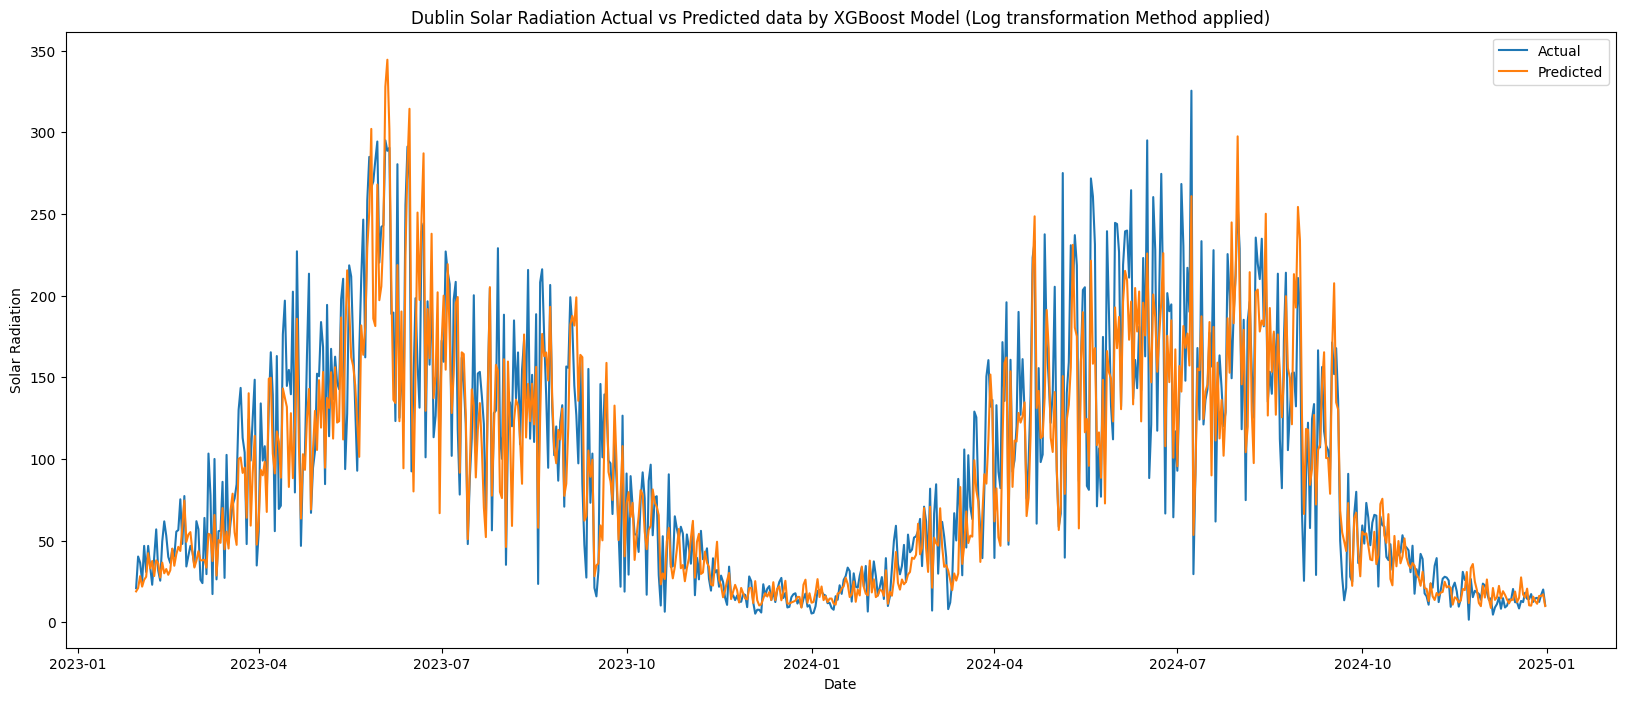

In [247]:
#y_test =y_test.reset_index(drop=True)
plt.figure(figsize =(20,8))
plt.plot(y_test.index,y_test, label='Actual')
plt.plot(y_test.index,pred,label='Predicted')
plt.title('Dublin Solar Radiation Actual vs Predicted data by XGBoost Model (Log transformation Method applied)')
plt.xlabel('Date')
plt.ylabel('Solar Radiation')
plt.legend()
plt.show()

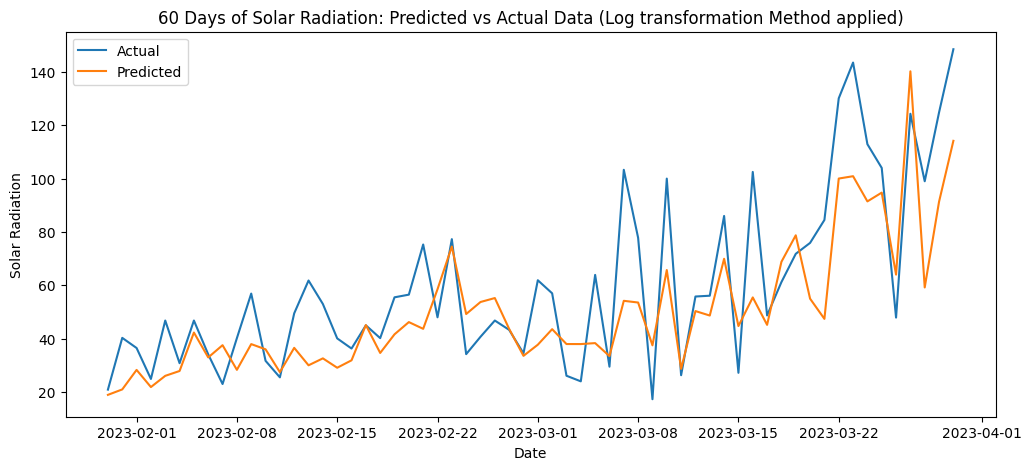

In [251]:
plt.figure(figsize=(12,5))
#t=test['solarradiation']
plt.plot(y_test[:60], label="Actual")
plt.plot(y_test.index[:60],pred[:60], label="Predicted")
plt.legend()
plt.ylabel('Solar Radiation')
plt.xlabel('Date')
plt.title("60 Days of Solar Radiation: Predicted vs Actual Data (Log transformation Method applied)")
plt.show()

## Statistics Evaluation Metrics

In [252]:
# Calculate metrics
rmse = np.sqrt(mean_squared_error(y_test, pred))
mae = mean_absolute_error(y_test, pred)
r2 = r2_score(y_test, pred)
mape =mean_absolute_percentage_error(y_test, pred)
# Print them
print(f'RMSE: {rmse:.4f}')
print(f'MAE: {mae:.4f}')
print(f'R² score: {r2:.4f}')
print(f'MAPE: {mape:.4f}')

RMSE: 30.5330
MAE: 21.5805
R² score: 0.8327
MAPE: 0.3130


In [77]:
# Symmetric Mean Absolute Percentae Error Function
def smape(test, pred):
    test, pred = np.array(y_test), np.array(pred)
    return 100 * np.mean(2 * np.abs(pred - test) /
                         (np.abs(test) + np.abs(pred) + 1e-8))


In [253]:
print("SMAPE:", smape(y_test, pred))


SMAPE: 27.709251883132264


### Best parameters by randomizedserachcv

A parameters grid in the form of a python dictionary with names a values.

In [65]:
#range of parameters
param_range = {
    'n_estimators': randint(100, 2000),
    "learning_rate": loguniform(0.001, 0.3),
    'max_depth': randint(3, 12),
    "gamma": loguniform(1e-8, 10),
    "min_child_weight": loguniform(0.01, 20),
    'subsample': uniform(0.5, 0.5),
    'colsample_bytree': uniform(0.5, 0.5),
    "colsample_bylevel": uniform(0.5, 0.5),
    "colsample_bynode": uniform(0.5, 0.5),
    "reg_alpha": loguniform(1e-8, 10),                 
    "reg_lambda": loguniform(1e-8, 10),
    "max_bin": randint(128, 512),
    "grow_policy": ["depthwise", "lossguide"],
    "max_leaves": randint(0, 256),
  #  "tree_method": ["gpu_hist"],
}

In [66]:
model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

Randomized Search samples random combinations for a predefined number of iterations from the hyperparameter grid

In [21]:
search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_range,
    n_iter=20,                    
    scoring="neg_root_mean_squared_error", 
    cv=5,
    verbose=3,
    n_jobs=-1
)

In [67]:
search.fit(X_train,y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,estimator,"XGBRegressor(...ree=None, ...)"
,param_distributions,"{'colsample_bylevel': <scipy.stats....001AB0BFEBB60>, 'colsample_bynode': <scipy.stats....001AB0BFE98E0>, 'colsample_bytree': <scipy.stats....001AB0BFEAA50>, 'gamma': <scipy.stats....001AB0BFEAD50>, ...}"
,n_iter,20
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,3
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [68]:
search.best_params_

{'colsample_bylevel': np.float64(0.9813618208856627),
 'colsample_bynode': np.float64(0.7723611356639745),
 'colsample_bytree': np.float64(0.8933958310918912),
 'gamma': np.float64(5.824605789004581e-05),
 'grow_policy': 'depthwise',
 'learning_rate': np.float64(0.010874089654938243),
 'max_bin': 136,
 'max_depth': 4,
 'max_leaves': 92,
 'min_child_weight': np.float64(0.03954735160615236),
 'n_estimators': 1786,
 'reg_alpha': np.float64(2.3113081104602487e-06),
 'reg_lambda': np.float64(0.7171531774969244),
 'subsample': np.float64(0.6296283765042505)}

In [69]:
search.best_score_

np.float64(-0.36792605823516344)

In [70]:
model_best = XGBRegressor(objective='reg:squarederror',random_state=42,
colsample_bylevel= float(0.9813618208856627),
 colsample_bynode=float(0.7723611356639745),
 colsample_bytree= float(0.8933958310918912),
 gamma= float(5.824605789004581e-05),
 grow_policy= 'depthwise',
 learning_rate= float(0.010874089654938243),
 max_bin= 136,
 max_depth=(4),
 max_leaves= 92,
 min_child_weight= float(0.03954735160615236),
 n_estimators= 1786,
 reg_alpha= float(2.3113081104602487e-06),
 reg_lambda= float(0.7171531774969244),
 subsample= float(0.6296283765042505))          


In [71]:
model_best.fit(
    X_train, y_train,
    verbose=False
)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,0.9813618208856627
,colsample_bynode,0.7723611356639745
,colsample_bytree,0.8933958310918912
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


### Predict

In [72]:
pred_best = model_best.predict(X_test)

## Inverse Transformation

In [73]:
pred = np.expm1(pred_best)
y_test=np.expm1(y_test)

## Plot Actual vs Prediction

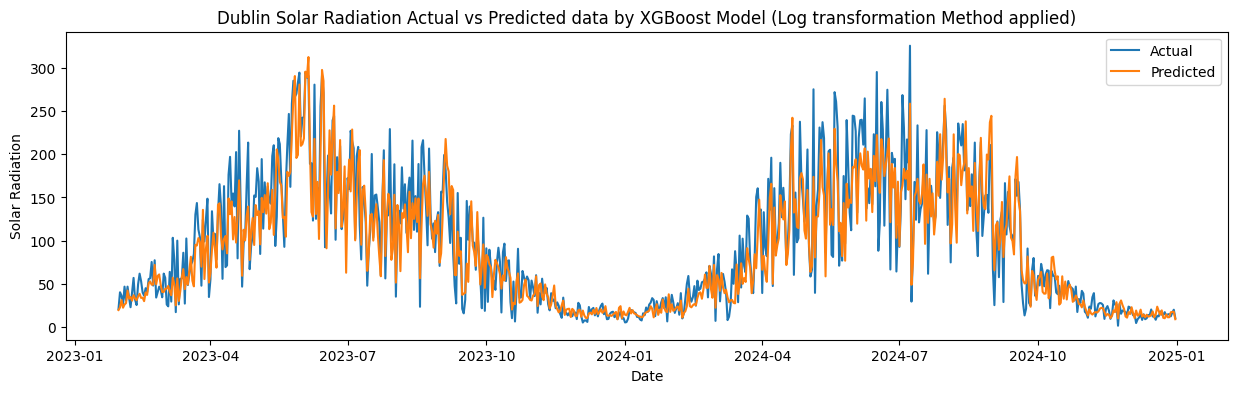

In [78]:
#y_test =y_test.reset_index(drop=True)
plt.figure(figsize =(15,4))
plt.plot(y_test.index,y_test, label='Actual')
plt.plot(y_test.index,pred,label='Predicted')
plt.title('Dublin Solar Radiation Actual vs Predicted data by XGBoost Model (Log transformation Method applied)')
plt.xlabel('Date')
plt.ylabel('Solar Radiation')
plt.legend()
plt.show()

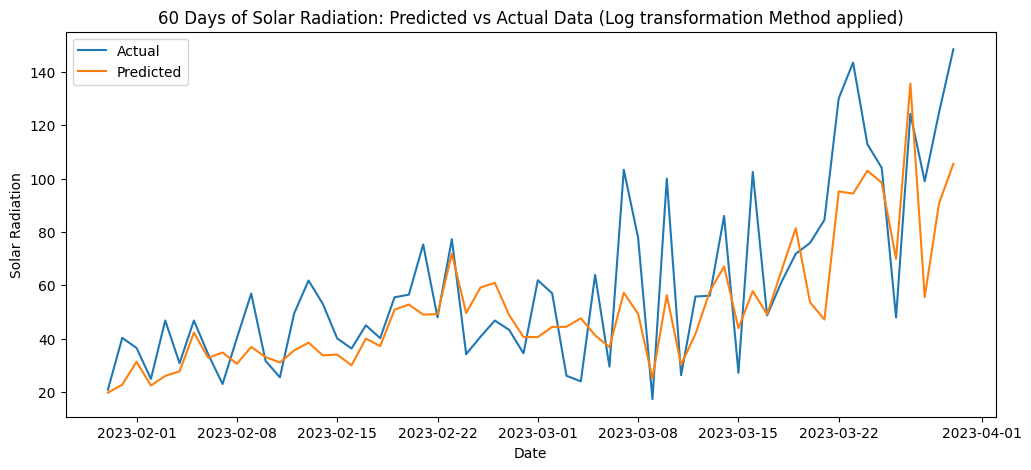

In [75]:
plt.figure(figsize=(12,5))
#t=test['solarradiation']
plt.plot(y_test[:60], label="Actual")
plt.plot(y_test.index[:60],pred[:60], label="Predicted")
plt.legend()
plt.ylabel('Solar Radiation')
plt.xlabel('Date')
plt.title("60 Days of Solar Radiation: Predicted vs Actual Data (Log transformation Method applied)")
plt.show()

## Statistics Evaluation Metrics

In [76]:
# Calculate metrics
rmse = np.sqrt(mean_squared_error(y_test, pred))
mae = mean_absolute_error(y_test, pred)
r2 = r2_score(y_test, pred)
mape =mean_absolute_percentage_error(y_test, pred)
# Print them
print(f'RMSE: {rmse:.4f}')
print(f'MAE: {mae:.4f}')
print(f'R² score: {r2:.4f}')
print(f'MAPE: {mape:.4f}')

RMSE: 29.2118
MAE: 20.7609
R² score: 0.8468
MAPE: 0.3020


# Experiment 4:
To develop a forecasting Model using XGBoost algorithm utilising **Cross-validation** technique. 


## Libraries

In [93]:
# Data manipulation
import pandas as pd
import numpy as np
##Plots
import matplotlib.pyplot as plt
import seaborn as sns

#Split the data
from sklearn.model_selection import train_test_split

#XGBoost model
from xgboost import XGBRegressor

# Statistical Evaluation Metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from math import sqrt

#randomized seach CV
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform
import random
#timesplit
from sklearn.model_selection import TimeSeriesSplit
import warnings
warnings.filterwarnings('ignore')

## Load the Dataset

In [94]:
df = pd.read_csv('dublin_2015_to_2024_final.csv',parse_dates=["datetime"])
df.head()

,datetime,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation
0,2015-01-01,13.6,82.9,4.786,95.8,64.0,220.5,1013.4,86.1,17.1,8.8
1,2015-01-02,7.0,73.1,0.451,68.5,40.9,241.5,1026.9,49.4,20.9,39.2
2,2015-01-03,6.1,93.9,7.283,37.1,28.1,301.3,1023.8,64.0,15.6,16.9
3,2015-01-04,6.8,93.5,0.000,33.8,13.1,191.4,1031.3,54.9,18.9,20.1
4,2015-01-05,10.7,88.6,0.026,41.4,25.5,182.2,1021.3,89.5,19.8,9.8


## Split into Train and Test data (80/20)

In [95]:
df.set_index("datetime", inplace=True)
df = df.sort_index()

In [256]:
# Separate historical and future data
train = df.loc[df.index < '2022-12-31']
test = df.loc[df.index >= '2022-12-31'].copy()

In [5]:
test

,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation
datetime,,,,,,,,,,
2022-12-31,9.9,93.0,1.523,23.4,13.8,212.2,991.8,89.9,13.4,13.0
2023-01-01,6.8,91.8,0.735,36.4,17.9,241.6,1000.4,77.0,15.2,10.6
2023-01-02,5.9,84.8,0.000,46.1,24.8,222.7,1014.4,44.6,15.6,22.2
2023-01-03,13.0,85.1,0.849,78.1,36.0,202.6,1004.4,87.0,16.6,15.8
2023-01-04,12.8,79.4,0.314,64.8,35.1,252.6,1008.0,77.1,15.7,18.2
...,...,...,...,...,...,...,...,...,...,...
2024-12-27,9.9,95.4,0.075,17.6,12.7,201.7,1030.8,90.8,9.5,15.0
2024-12-28,9.1,90.2,0.002,31.7,17.8,232.8,1027.7,83.9,17.0,12.5
2024-12-29,9.9,86.2,0.078,48.2,29.1,241.1,1026.8,77.1,16.4,16.8


## Forecasting Horizon

In [257]:
# target feature
target='solarradiation'

In [258]:
# exogenous variables 
exogenous = ['tempmax','humidity','precip','windgust','windspeed',
             'winddir','sealevelpressure','cloudcover','visibility']


### Making lagg features

In [259]:
# funtion to make lagg features
def make_features(data):
    data = data.copy()
    
    #Target lags function
    for lag in range(1, 31):  #create 30 laggs
        data[f'{target}_lag{lag}'] = data[target].shift(lag)
    
    # exogenous laggs function
    for col in exogenous:
        for lag in range(1, 31): #create 30 lags of each feature
            data[f'{col}_lag{lag}'] = data[col].shift(lag)
    
  
  
    return data

In [260]:
train = make_features(train).dropna()
test  = make_features(test).dropna()

In [10]:
train.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2891 entries, 2015-01-31 to 2022-12-30
Columns: 310 entries, tempmax to visibility_lag30
dtypes: float64(310)
memory usage: 6.9 MB


In [11]:
train.columns

Index(['tempmax', 'humidity', 'precip', 'windgust', 'windspeed', 'winddir',
       'sealevelpressure', 'cloudcover', 'visibility', 'solarradiation',
       ...
       'visibility_lag21', 'visibility_lag22', 'visibility_lag23',
       'visibility_lag24', 'visibility_lag25', 'visibility_lag26',
       'visibility_lag27', 'visibility_lag28', 'visibility_lag29',
       'visibility_lag30'],
      dtype='object', length=310)

In [261]:
# Function to add features exepts for solarradiation
features = [c for c in train.columns if c != target]


In [13]:
features

['tempmax',
 'humidity',
 'precip',
 'windgust',
 'windspeed',
 'winddir',
 'sealevelpressure',
 'cloudcover',
 'visibility',
 'solarradiation_lag1',
 'solarradiation_lag2',
 'solarradiation_lag3',
 'solarradiation_lag4',
 'solarradiation_lag5',
 'solarradiation_lag6',
 'solarradiation_lag7',
 'solarradiation_lag8',
 'solarradiation_lag9',
 'solarradiation_lag10',
 'solarradiation_lag11',
 'solarradiation_lag12',
 'solarradiation_lag13',
 'solarradiation_lag14',
 'solarradiation_lag15',
 'solarradiation_lag16',
 'solarradiation_lag17',
 'solarradiation_lag18',
 'solarradiation_lag19',
 'solarradiation_lag20',
 'solarradiation_lag21',
 'solarradiation_lag22',
 'solarradiation_lag23',
 'solarradiation_lag24',
 'solarradiation_lag25',
 'solarradiation_lag26',
 'solarradiation_lag27',
 'solarradiation_lag28',
 'solarradiation_lag29',
 'solarradiation_lag30',
 'tempmax_lag1',
 'tempmax_lag2',
 'tempmax_lag3',
 'tempmax_lag4',
 'tempmax_lag5',
 'tempmax_lag6',
 'tempmax_lag7',
 'tempmax_lag8

### Creating X_train, y_train, X_test, y_test

In [262]:
X_train, y_train = train[features], train[target]
X_test,  y_test  = test[features],  test[target]

## Cross-validation function

In [270]:
fold_scores = []
accuracy_histories = []
loss_histories = []

# time-series CV splitter
tss = TimeSeriesSplit(
    n_splits=5,
    test_size=30,   # 30 days 
    gap=1             
)

for fold, (tr_idx, val_idx) in enumerate(tss.split(X_train), start=1):
    X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

    model_cv = XGBRegressor(
        n_estimators=200,
        learning_rate=0.01,
        objective="reg:squarederror",
        random_state=42
    )

    model_cv.fit(
        X_tr, y_tr,
        eval_set=[(X_val, y_val)],  
        verbose=False
    )
        
#pred
    y_pred = model_cv.predict(X_val)

    mape=mean_absolute_percentage_error(y_val, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    mae  = mean_absolute_error(y_val, y_pred)
    r2   = r2_score(y_val, y_pred)

    fold_scores.append(rmse)
    fold_scores.append(mae)
    fold_scores.append(r2)
    fold_scores.append(mape)



In [271]:
fold_scores

[np.float64(33.27348116281975),
 26.488849995930988,
 0.5611074232557506,
 0.1955308151019036,
 np.float64(35.366218531355415),
 28.362091827392582,
 -0.08533875222177145,
 0.5230968054391917,
 np.float64(22.032463669085562),
 17.106723810831706,
 0.1490388823003842,
 0.5450724825108129,
 np.float64(15.35771814269031),
 12.708496640523276,
 -0.7128974400595776,
 0.6666196848568261,
 np.float64(13.901011127110424),
 13.531034978230794,
 -13.101483357356296,
 0.8400060604757427]

In [272]:
fold_scores = np.array(fold_scores)
fold_score = pd.DataFrame(fold_scores.reshape(5, 4),
                       columns=['rmse','mae','r2','mape'])
fold_score

,rmse,mae,r2,mape
0,33.273481,26.488850,0.561107,0.195531
1,35.366219,28.362092,-0.085339,0.523097
2,22.032464,17.106724,0.149039,0.545072
3,15.357718,12.708497,-0.712897,0.666620
4,13.901011,13.531035,-13.101483,0.840006


In [273]:
print("Mean RMSE:", np.mean(fold_scores[0]))
print("Mean MAE:", np.mean(fold_scores[1]))
print("Mean R2 Score:", np.mean(fold_scores[2]))
print("Mean MAPE:", np.mean(fold_scores[3]))

Mean RMSE: 33.27348116281975
Mean MAE: 26.488849995930988
Mean R2 Score: 0.5611074232557506
Mean MAPE: 0.1955308151019036


# Experiment 5:
Predict future. Forecasting 30 days ahead.

## Libraries

In [1]:
# Data manipulation
import pandas as pd
import numpy as np
##Plots
import matplotlib.pyplot as plt
import seaborn as sns

#Split the data
from sklearn.model_selection import train_test_split

#XGBoost model
from xgboost import XGBRegressor

# Statistical Evaluation Metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from math import sqrt

#randomized seach CV
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform
import random
from collections import deque


## Load the Dataset

In [96]:
df = pd.read_csv('dublin_2015_to_2024_final.csv',parse_dates=["datetime"])
df.head()

,datetime,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation
0,2015-01-01,13.6,82.9,4.786,95.8,64.0,220.5,1013.4,86.1,17.1,8.8
1,2015-01-02,7.0,73.1,0.451,68.5,40.9,241.5,1026.9,49.4,20.9,39.2
2,2015-01-03,6.1,93.9,7.283,37.1,28.1,301.3,1023.8,64.0,15.6,16.9
3,2015-01-04,6.8,93.5,0.000,33.8,13.1,191.4,1031.3,54.9,18.9,20.1
4,2015-01-05,10.7,88.6,0.026,41.4,25.5,182.2,1021.3,89.5,19.8,9.8


In [97]:
df.set_index("datetime", inplace=True)
df = df.sort_index()

## Forecasting Horizon

In [98]:
# target feature
target='solarradiation'

In [99]:
# exogenous variables 
exogenous = ['tempmax','humidity','precip','windgust','windspeed',
             'winddir','sealevelpressure','cloudcover','visibility']


### Making lagg features

In [100]:
# funtion to make lagg features
def make_features(data):
    data = data.copy()
    
    #Target lags function
    for lag in range(1, 31):  #create 30 laggs
        data[f'{target}_lag{lag}'] = data[target].shift(lag)
    
    # exogenous laggs function
    for col in exogenous:
        for lag in range(1, 31): #create 30 lags of each feature
            data[f'{col}_lag{lag}'] = data[col].shift(lag)
    
    return data

In [101]:
df_train = make_features(df).dropna()

In [102]:
# Function to list features exepts for solarradiation
features = [c for c in df_train.columns if c != target]


In [105]:
features

['tempmax',
 'humidity',
 'precip',
 'windgust',
 'windspeed',
 'winddir',
 'sealevelpressure',
 'cloudcover',
 'visibility',
 'solarradiation_lag1',
 'solarradiation_lag2',
 'solarradiation_lag3',
 'solarradiation_lag4',
 'solarradiation_lag5',
 'solarradiation_lag6',
 'solarradiation_lag7',
 'solarradiation_lag8',
 'solarradiation_lag9',
 'solarradiation_lag10',
 'solarradiation_lag11',
 'solarradiation_lag12',
 'solarradiation_lag13',
 'solarradiation_lag14',
 'solarradiation_lag15',
 'solarradiation_lag16',
 'solarradiation_lag17',
 'solarradiation_lag18',
 'solarradiation_lag19',
 'solarradiation_lag20',
 'solarradiation_lag21',
 'solarradiation_lag22',
 'solarradiation_lag23',
 'solarradiation_lag24',
 'solarradiation_lag25',
 'solarradiation_lag26',
 'solarradiation_lag27',
 'solarradiation_lag28',
 'solarradiation_lag29',
 'solarradiation_lag30',
 'tempmax_lag1',
 'tempmax_lag2',
 'tempmax_lag3',
 'tempmax_lag4',
 'tempmax_lag5',
 'tempmax_lag6',
 'tempmax_lag7',
 'tempmax_lag8

### Creating X_train, y_train

In [106]:
X_train, y_train = df_train[features], df_train[target]

## XGBoost Model

In [107]:
model = XGBRegressor(n_estimators=200,max_depth=3, learning_rate=0.1,objective='reg:squarederror',random_state=42)

In [108]:
model.fit(X_train,y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


### Generate future exogenous data

This function generates realistic values using DoY median for each day of year

In [155]:
def generate_future_exogenous(df, future_index, exogenous):
    df_ex = pd.DataFrame(index=future_index)

    # group by day-of-year and calculate median
    seasonal_median = df.groupby(df.index.dayofyear)[exogenous].median()
   #loop for each day
    for date in future_index:
        day = date.dayofyear #DOY time 
        if day in seasonal_median.index: #supply doy value
            df_ex.loc[date, exogenous] = seasonal_median.loc[day].values
        
    return df_ex


### Generate index for 30 days

In [156]:
future_index = pd.date_range(
    start='2025-01-01',
    periods=30,
    freq="D"
)


## Generate future dataframe

In [157]:
future = generate_future_exogenous(df_train, future_index, features)


In [158]:
future.head()

,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation_lag1,...,visibility_lag21,visibility_lag22,visibility_lag23,visibility_lag24,visibility_lag25,visibility_lag26,visibility_lag27,visibility_lag28,visibility_lag29,visibility_lag30
2025-01-01,7.4,84.7,0.735,56.2,29.3,241.6,1007.5,60.1,15.5,18.1,...,17.1,15.6,17.1,16.6,17.3,15.7,15.4,18.4,15.6,17.2
2025-01-02,9.9,84.4,0.200,59.4,28.7,225.6,1009.4,55.3,16.1,14.2,...,14.9,17.1,15.6,17.1,16.6,17.3,15.7,15.4,18.4,15.6
2025-01-03,7.9,85.2,0.652,52.9,30.8,251.2,1004.4,64.0,16.9,11.6,...,15.9,14.9,17.1,15.6,17.1,16.6,17.3,15.7,15.4,18.4
2025-01-04,7.1,85.9,0.078,45.7,23.9,240.1,1008.0,71.4,16.9,14.8,...,18.6,15.9,14.9,17.1,15.6,17.1,16.6,17.3,15.7,15.4
2025-01-05,6.9,85.4,0.005,41.0,23.1,217.7,1017.1,71.1,18.0,23.8,...,18.2,18.6,15.9,14.9,17.1,15.6,17.1,16.6,17.3,15.7


## Generate Predictions

In [161]:
n_lags = 30   # create 30 day laggs
future_predicts = [] #list

# deque builds a rolling buffer(queue) window of 30 last real days
lag_buffer = deque(df_train[target].iloc[-n_lags:].values, maxlen=n_lags)

for date in future_index:

    row = future.loc[[date]].copy() #selects one row for that specific day

    #create 30 lag features
    for lag in range(1, n_lags + 1):
        row[f'lag{lag}'] = lag_buffer[-lag]  # lag1 = most recent

    #Match model feature order-
    row = row.reindex(columns=features, fill_value=0)

    # predict next day
    pred = model.predict(row)[0]
    future_predicts.append(pred)




### Create a datame with Predicted values

In [162]:
forecast = pd.DataFrame(
    {target: future_predicts},
    index=future_index
)


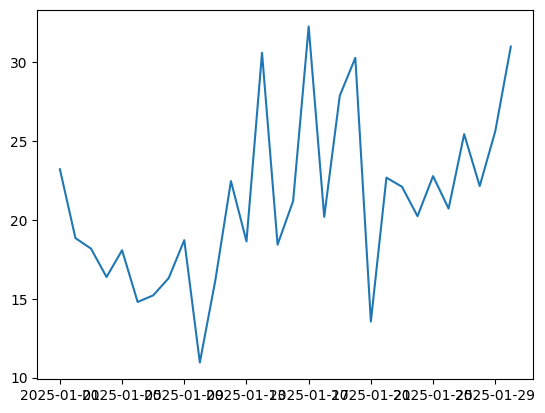

In [163]:
plt.plot(forecast[target])

## Plot History and Predicted data

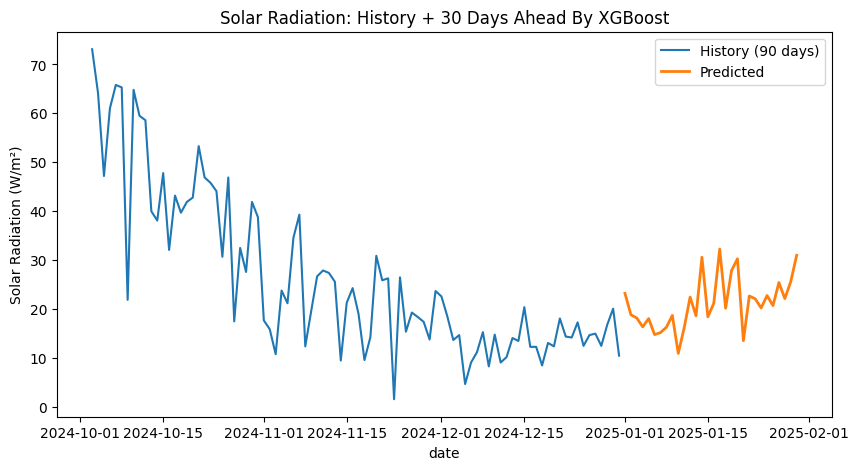

In [167]:
plt.figure(figsize=(10,5))
plt.plot(df[target].iloc[-90:], label="History (90 days)")
plt.plot(forecast[target], label="Predicted", linewidth=2)
plt.legend()
plt.ylabel('Solar Radiation (W/m²)')
plt.xlabel('date')
plt.title('Solar Radiation: History + 30 Days Ahead By XGBoost')
plt.show()


In [166]:
forecast.to_csv('forecast_by_xgboost.csv',index=True)